In [1]:
import os
import io
import glob
import copy
import random
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

from torchvision import datasets, transforms, models
from torchvision.models import resnet18, ResNet18_Weights

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

seed = 42
rng = random.Random(seed)

Using device: cuda


In [2]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.247, 0.243, 0.261])
])

train_dataset_full = datasets.CIFAR10(root='./cifar-10-batches-py', train=True,
                                      download=True, transform=transform)
test_dataset_full = datasets.CIFAR10(root='./cifar-10-batches-py', train=False,
                                     download=True, transform=transform)

train_dataset = train_dataset_full
test_dataset = test_dataset_full

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("train - test dataset ready.")

Files already downloaded and verified
Files already downloaded and verified
train - test dataset ready.


In [3]:
def load_model(path="full_model.pth"):
    print("\nLoading pretrained ResNet18 model...")
    model = resnet18(weights=ResNet18_Weights.DEFAULT)

    # Modify final layer for 2 classes
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 10)

    # Freeze all layers except layer3, layer4, fc
    for param in model.parameters():
        param.requires_grad = False
    for layer in [model.layer3, model.layer4, model.fc]:
        for param in layer.parameters():
            param.requires_grad = True

    # Load fine-tuned weights if available
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        print(f"Loaded fine-tuned weights from '{path}'")
    else:
        print(f"Warning: '{path}' not found. Model is not fine-tuned yet.")

    return model.to(device)


model = load_model()
model.eval()



Loading pretrained ResNet18 model...
Loaded fine-tuned weights from 'full_model.pth'


/tmp/ipykernel_209358/1370779204.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(path, map_location=device))


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [4]:
class Encoder(nn.Module):
    def __init__(self, trained_model):
        super().__init__()
        self.features = nn.Sequential(
            trained_model.conv1,
            trained_model.bn1,
            trained_model.relu,
            trained_model.maxpool,
            trained_model.layer1,
            trained_model.layer2,
            trained_model.layer3
        )

    def forward(self, x):
        with torch.no_grad():
            return self.features(x)


encoder = Encoder(model).to(device)
encoder.eval()


Encoder(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

In [5]:
def denormalize(tensor):
    """Convert normalized tensor back to uint8 image (0–255)."""
    mean = torch.tensor([0.4914, 0.4822, 0.4465], device=tensor.device).view(3, 1, 1)
    std = torch.tensor([0.247, 0.243, 0.261], device=tensor.device).view(3, 1, 1)
    img = tensor * std + mean
    img = (img.clamp(0, 1) * 255).byte().permute(1, 2, 0).cpu().numpy()
    return img


def tensor_to_pil(tensor):
    """Convert tensor (C,H,W) -> PIL image."""
    return Image.fromarray(denormalize(tensor))


def get_file_size(img_pil, format="JPEG", quality=95):
    """Return file size in bytes when saving image."""
    buf = io.BytesIO()
    img_pil.save(buf, format=format, quality=quality)
    return buf.getbuffer().nbytes


def compress_to_target_size(img_tensor, target_bytes, step=5, min_q=5, max_q=95):
    """Compress an image tensor to JPEG until output size ≈ target_bytes."""
    img_np = denormalize(img_tensor)
    pil_img = Image.fromarray(img_np)
    q_low, q_high = min_q, max_q
    best_img = pil_img
    while q_low <= q_high:
        q_mid = (q_low + q_high) // 2
        buf = io.BytesIO()
        pil_img.save(buf, format='JPEG', quality=q_mid)
        size = buf.getbuffer().nbytes
        if abs(size - target_bytes) <= step:
            best_img = Image.open(buf).convert("RGB")
            break
        elif size > target_bytes:
            q_high = q_mid - 1
        else:
            q_low = q_mid + 1
            best_img = Image.open(buf).convert("RGB")
    return transforms.ToTensor()(best_img)


## Simple Decoders

### Simple Tanh Decoder

In [6]:
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decode = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        return self.decode(x)


Found 15 decoders in 'STanh_TargetAlpha' for evaluation.


=== Evaluating Decoder α=0.01, seed=127 ===


/tmp/ipykernel_209358/3158128553.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  decoder_curr.load_state_dict(torch.load(path, map_location=device))


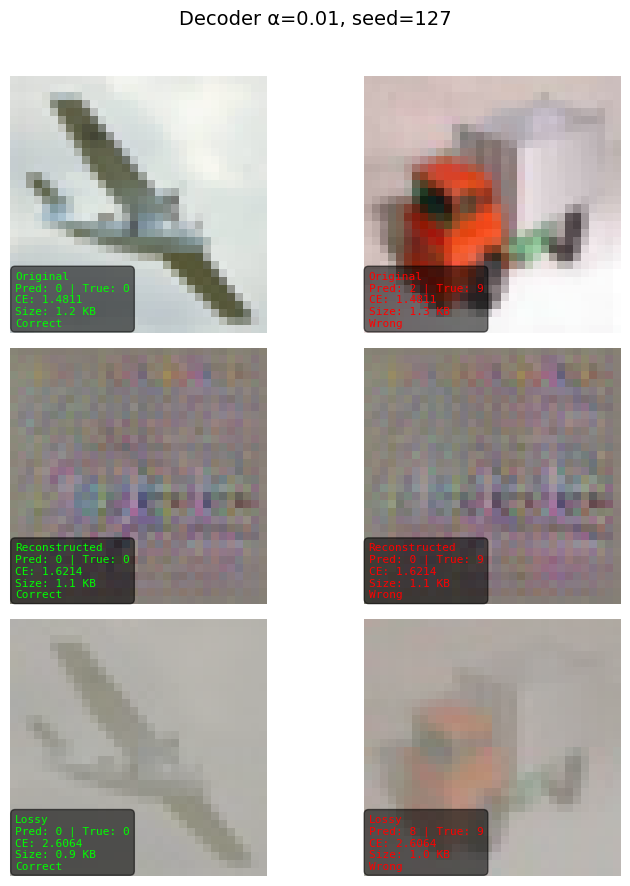


=== Evaluating Decoder α=0.01, seed=19 ===


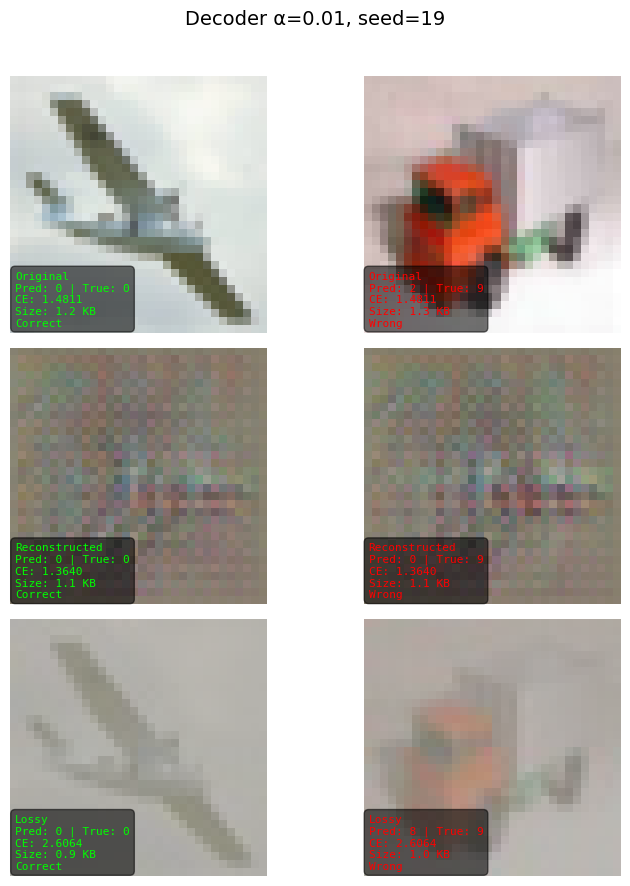


=== Evaluating Decoder α=0.01, seed=2 ===


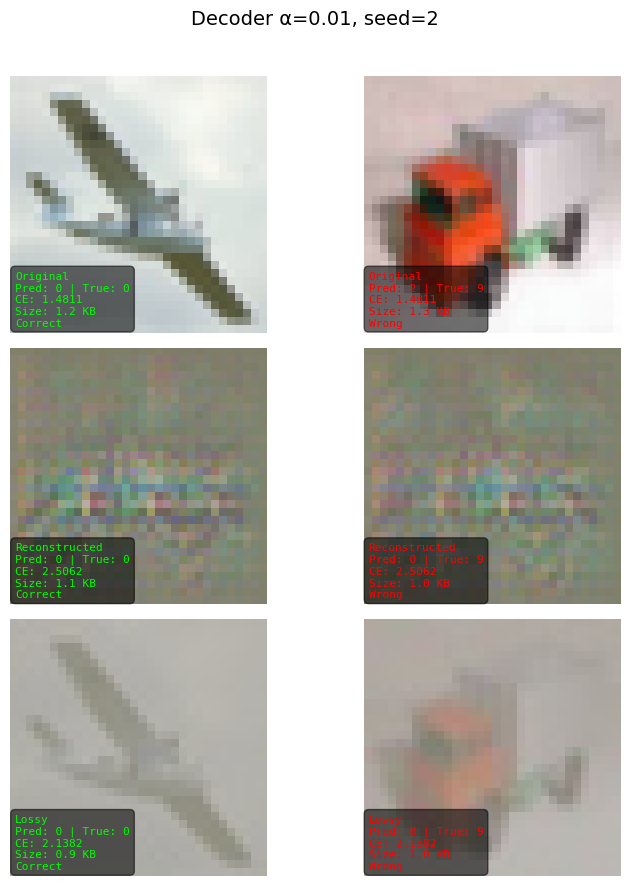


=== Evaluating Decoder α=0.01, seed=409 ===


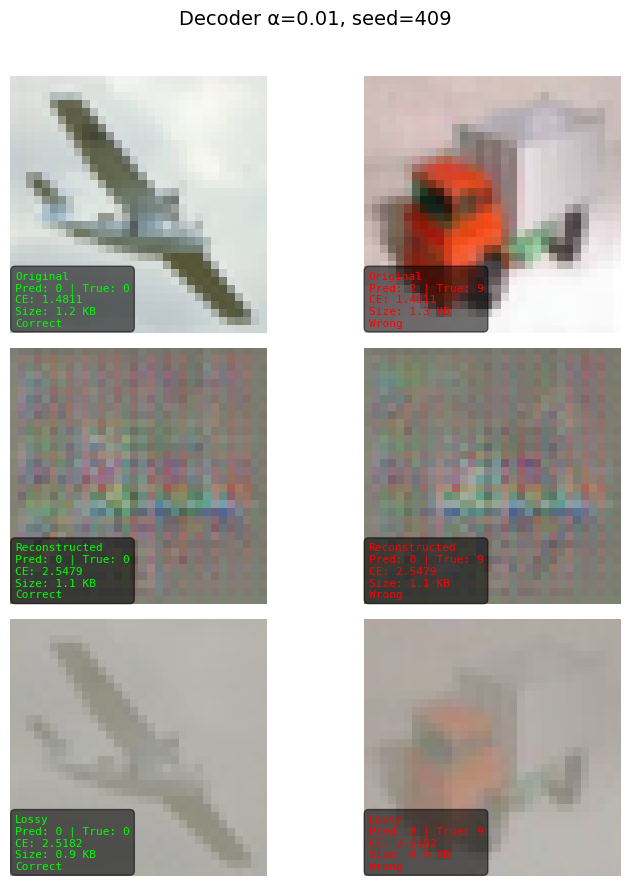


=== Evaluating Decoder α=0.01, seed=43 ===


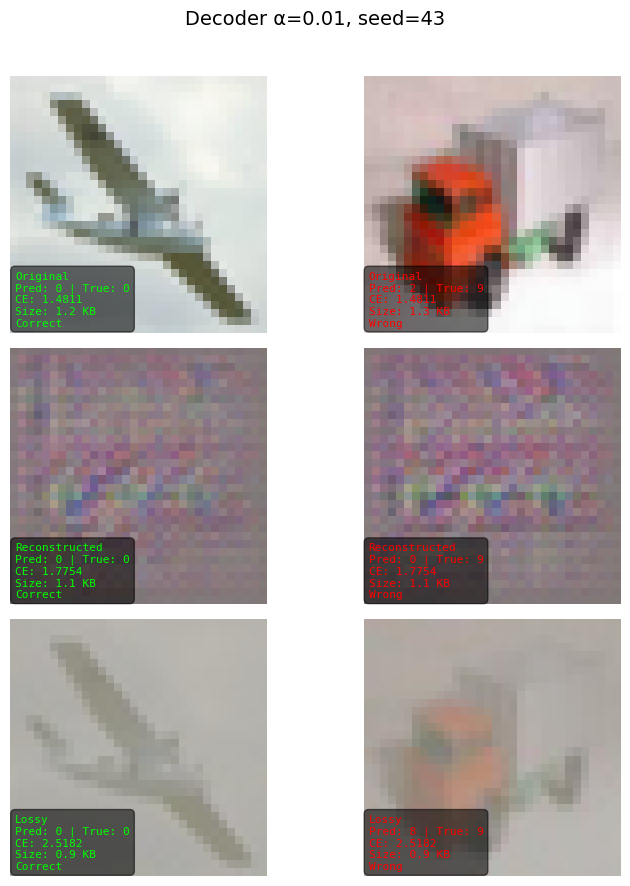


=== Evaluating Decoder α=0.41, seed=127 ===


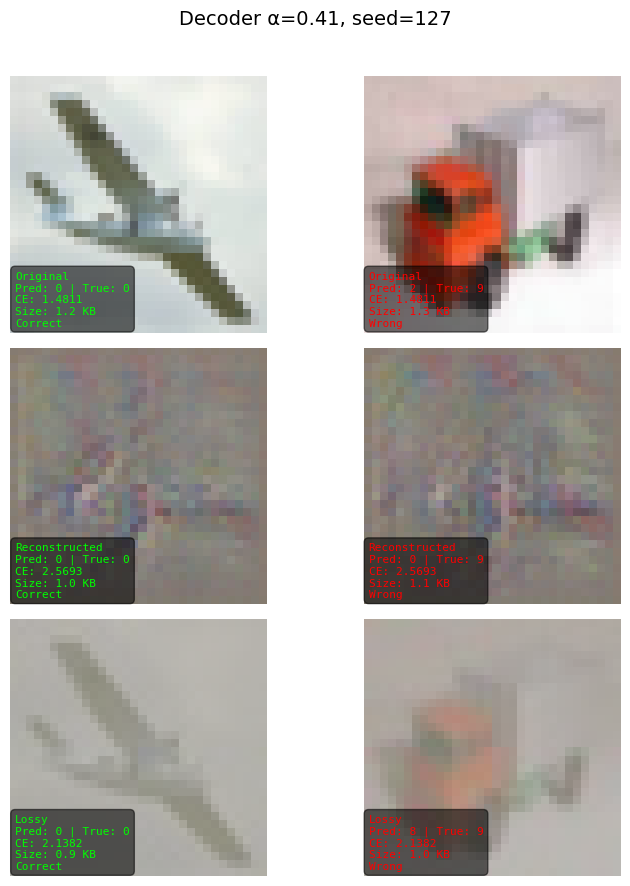


=== Evaluating Decoder α=0.41, seed=19 ===


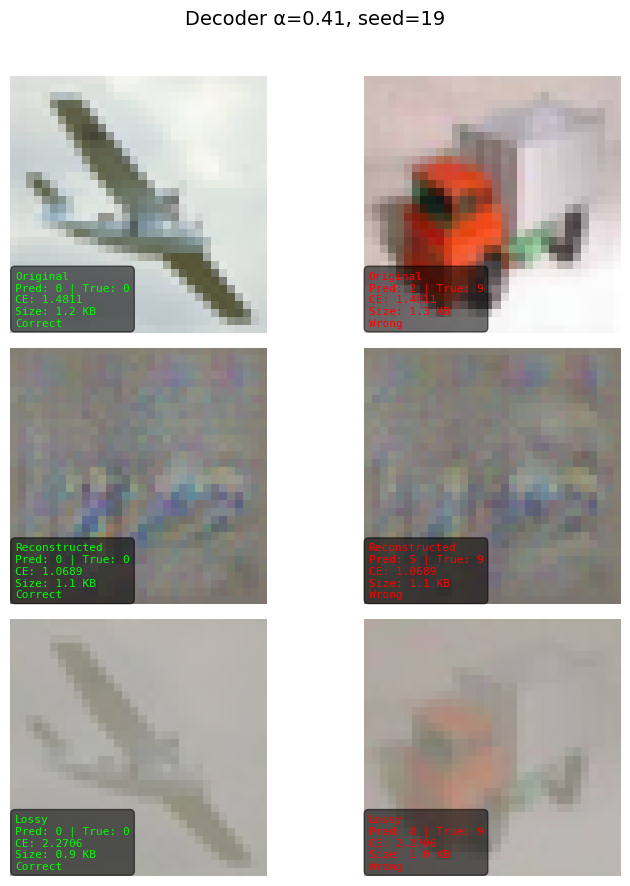


=== Evaluating Decoder α=0.41, seed=2 ===


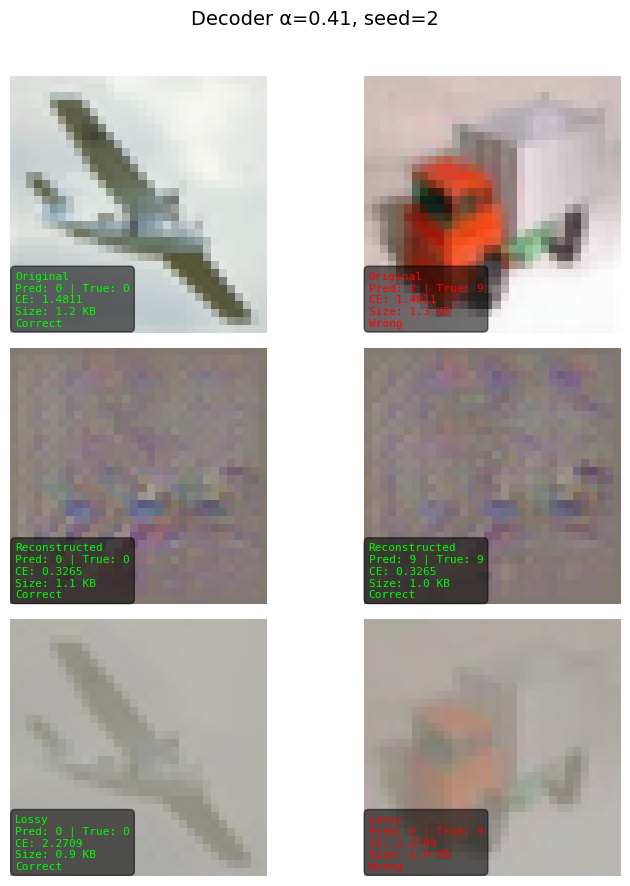


=== Evaluating Decoder α=0.41, seed=409 ===


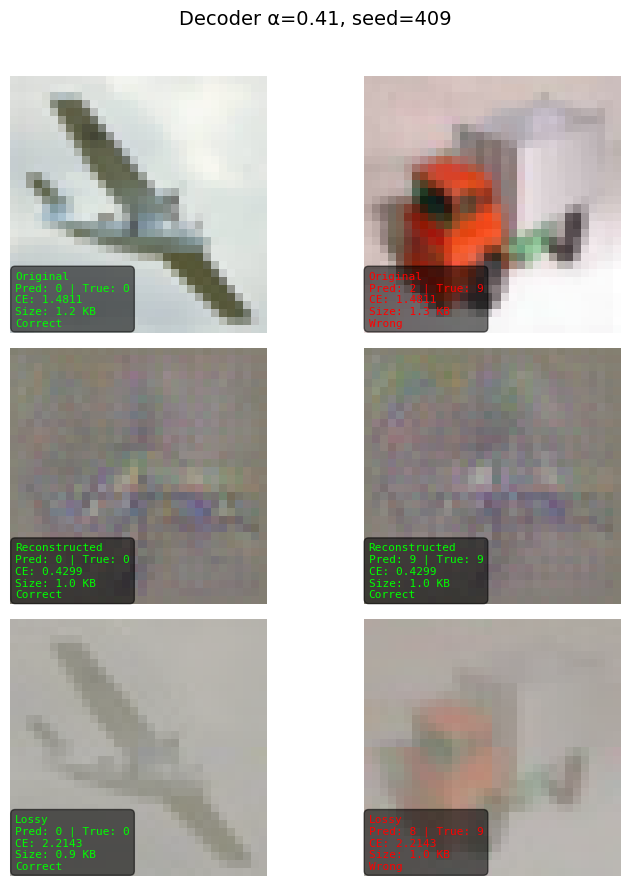


=== Evaluating Decoder α=0.41, seed=43 ===


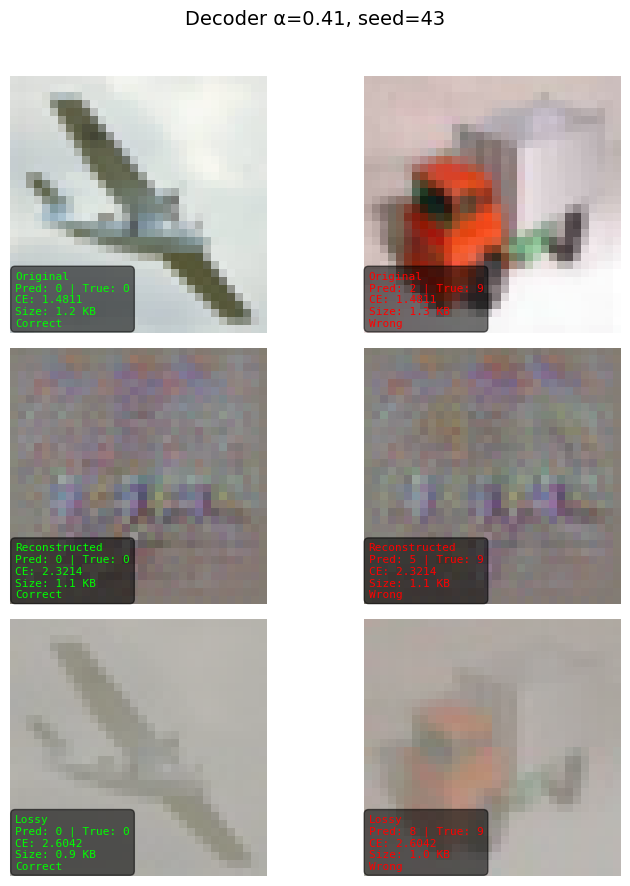


=== Evaluating Decoder α=0.45, seed=127 ===


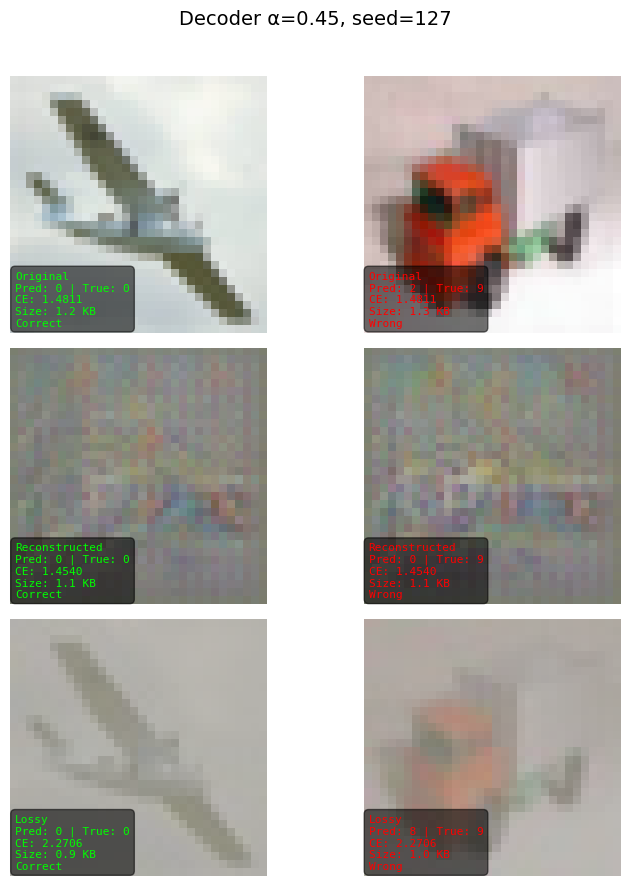


=== Evaluating Decoder α=0.45, seed=19 ===


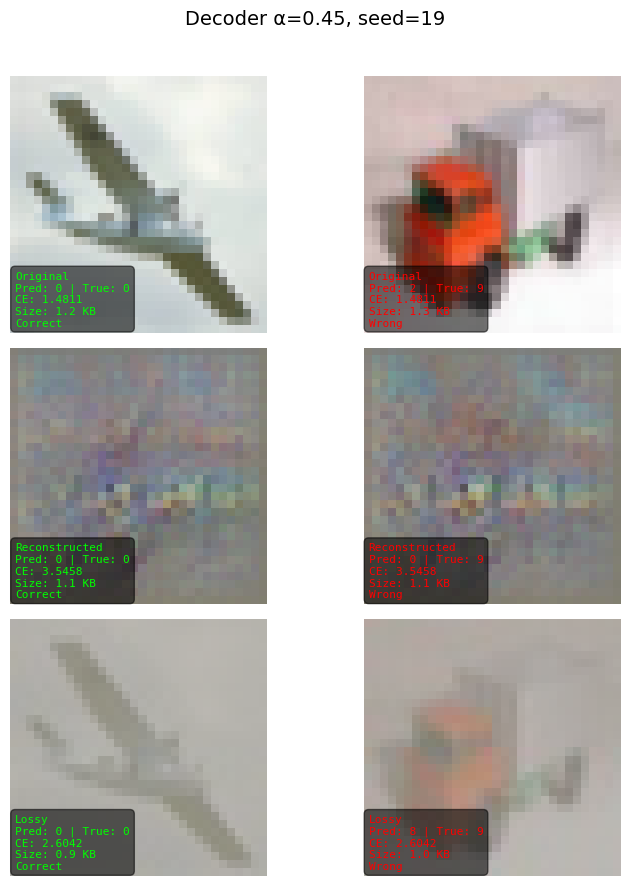


=== Evaluating Decoder α=0.45, seed=2 ===


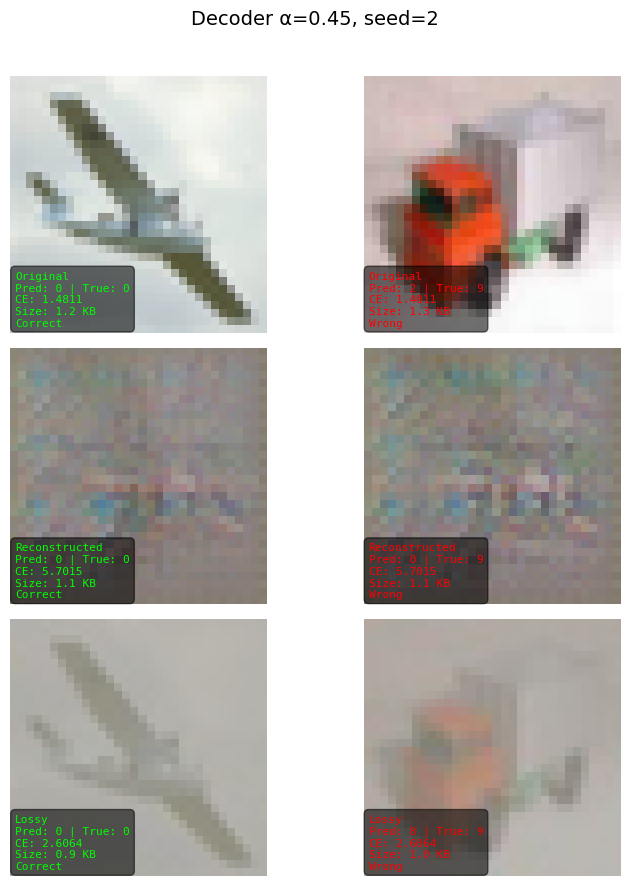


=== Evaluating Decoder α=0.45, seed=409 ===


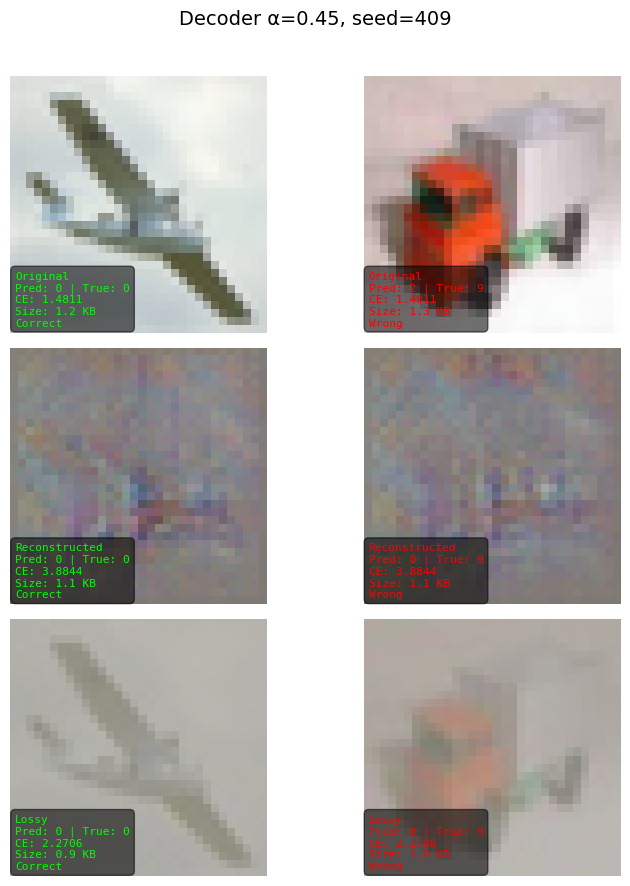


=== Evaluating Decoder α=0.45, seed=43 ===


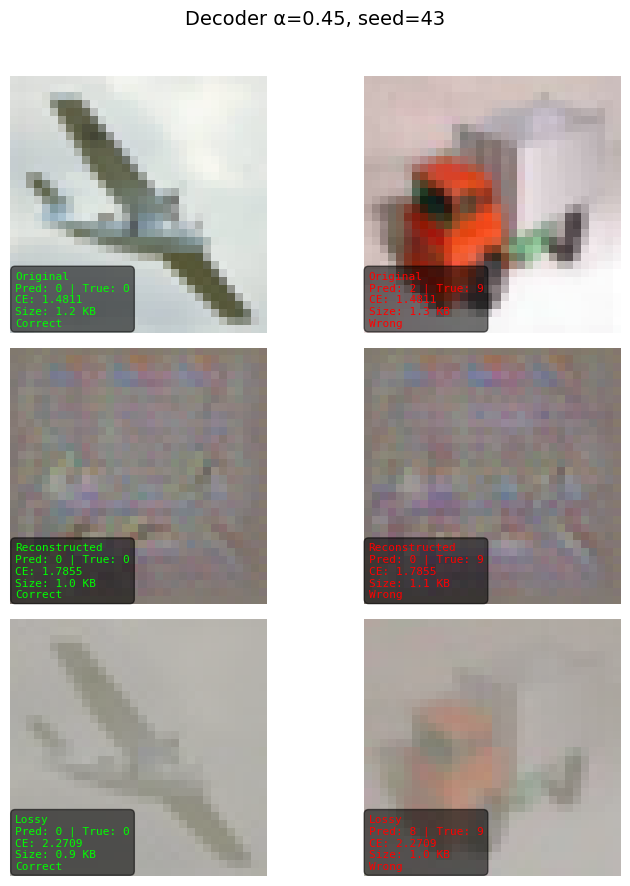

In [7]:
# Eval settings
save_dir = "STanh_TargetAlpha" 
decoder_paths = sorted(glob.glob(os.path.join(save_dir, "decoder*.pth")))
print(f"Found {len(decoder_paths)} decoders in '{save_dir}' for evaluation.\n")

criterion_ce = nn.CrossEntropyLoss()

# Pick 2 random images from test set
test_images, test_labels = [], []
for i in random.sample(range(len(test_loader.dataset)), 2):
    img, label = test_loader.dataset[i]
    test_images.append(img.unsqueeze(0))
    test_labels.append(torch.tensor(label))
test_images = torch.cat(test_images).to(device)
test_labels = torch.stack(test_labels).to(device)

# Loop over all saved decoders
for path in decoder_paths:
    fname = os.path.basename(path).replace(".pth", "")  # "decoder0.01_seed127"
    # Extract alpha and seed
    fname = fname.replace("decoder", "")  # "0.01_seed127"
    alpha_str, seed_str = fname.split("_seed")
    alpha_val = float(alpha_str)
    seed_val = int(seed_str)
    print(f"\n=== Evaluating Decoder α={alpha_val:.2f}, seed={seed_val} ===")

    # Load decoder
    decoder_curr = Decoder().to(device)
    decoder_curr.load_state_dict(torch.load(path, map_location=device))
    decoder_curr.eval()

    # Original
    with torch.no_grad():
        logits_orig = model(test_images)
        ce_orig = criterion_ce(logits_orig, test_labels).item()
        preds_orig = logits_orig.argmax(dim=1)
        acc_orig = (preds_orig == test_labels).float().mean().item()
    orig_sizes = [get_file_size(tensor_to_pil(img)) for img in test_images]

    # Recon
    with torch.no_grad():
        latents = encoder(test_images)
        recons = decoder_curr(latents)
        logits_recon = model(recons)
        ce_recon = criterion_ce(logits_recon, test_labels).item()
        preds_recon = logits_recon.argmax(dim=1)
        acc_recon = (preds_recon == test_labels).float().mean().item()
    recon_sizes = [get_file_size(tensor_to_pil(r)) for r in recons]

    # Lossy
    lossy_imgs = []
    for img in test_images:
        lossy_img = compress_to_target_size(img, target_bytes=int(np.mean(recon_sizes)))
        lossy_imgs.append(lossy_img.unsqueeze(0))
    lossy_batch = torch.cat(lossy_imgs).to(device)

    with torch.no_grad():
        logits_lossy = model(lossy_batch)
        ce_lossy = criterion_ce(logits_lossy, test_labels).item()
        preds_lossy = logits_lossy.argmax(dim=1)
        acc_lossy = (preds_lossy == test_labels).float().mean().item()
    lossy_sizes = [get_file_size(tensor_to_pil(l)) for l in lossy_batch]

    # Display
    fig, axs = plt.subplots(3, 2, figsize=(8, 9))
    fig.suptitle(f"Decoder α={alpha_val:.2f}, seed={seed_val}", fontsize=14)

    rows = ["Original", "Reconstructed", "Lossy"]
    imgs_show = [
        [test_images[0], test_images[1]],
        [recons[0], recons[1]],
        [lossy_batch[0], lossy_batch[1]],
    ]
    preds_all = [preds_orig, preds_recon, preds_lossy]
    ces_all = [ce_orig, ce_recon, ce_lossy]
    sizes_all = [orig_sizes, recon_sizes, lossy_sizes]

    for row in range(3):
        for col in range(2):
            ax = axs[row, col]
            ax.imshow(denormalize(imgs_show[row][col]) / 255)
            ax.axis("off")

            true_label = test_labels[col].item()
            pred_label = preds_all[row][col].item()
            correct = (true_label == pred_label)
            color = "lime" if correct else "red"

            # In-image caption box (bottom-left)
            stats = (
                f"{rows[row]}\n"
                f"Pred: {pred_label} | True: {true_label}\n"
                f"CE: {ces_all[row]:.4f}\n"
                f"Size: {sizes_all[row][col]/1024:.1f} KB\n"
                f"{'Correct' if correct else 'Wrong'}"
            )

            ax.text(
                0.02, 0.02, stats,
                transform=ax.transAxes,
                fontsize=8,
                color=color,
                va="bottom", ha="left",
                family="monospace",
                bbox=dict(facecolor="black", alpha=0.55, boxstyle="round,pad=0.4")
            )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


### Simple Sigmoid Decoder

In [8]:
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decode = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decode(x)


Found 15 decoders in 'SSigmoid_TargetAlpha' for evaluation.


=== Evaluating Decoder α=0.20, seed=127 ===


/tmp/ipykernel_209358/3710693245.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  decoder_curr.load_state_dict(torch.load(path, map_location=device))


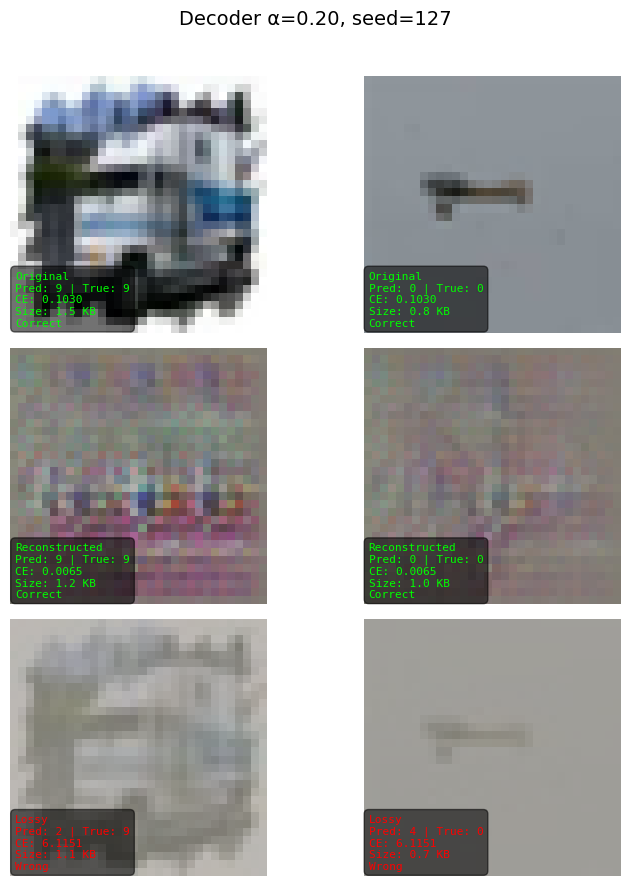


=== Evaluating Decoder α=0.20, seed=19 ===


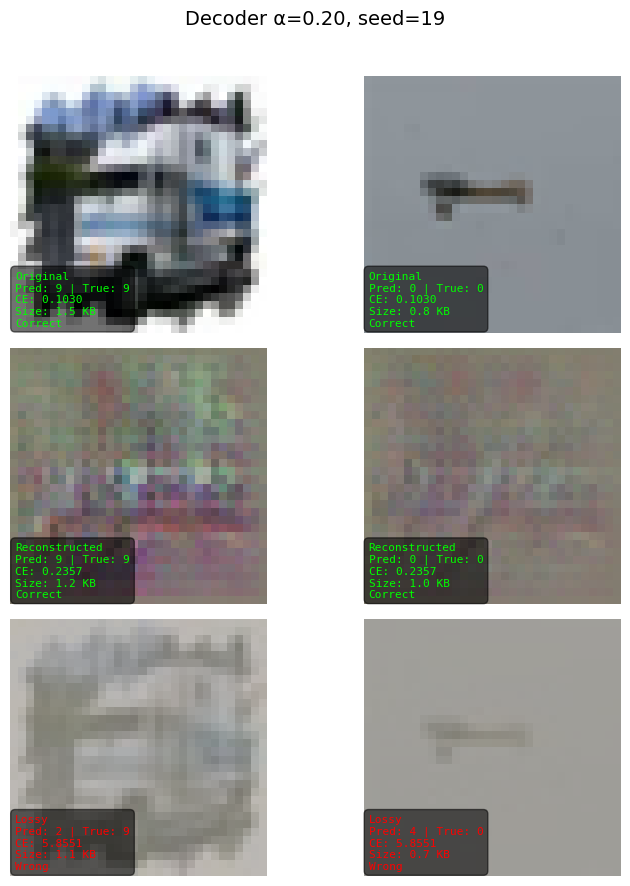


=== Evaluating Decoder α=0.20, seed=2 ===


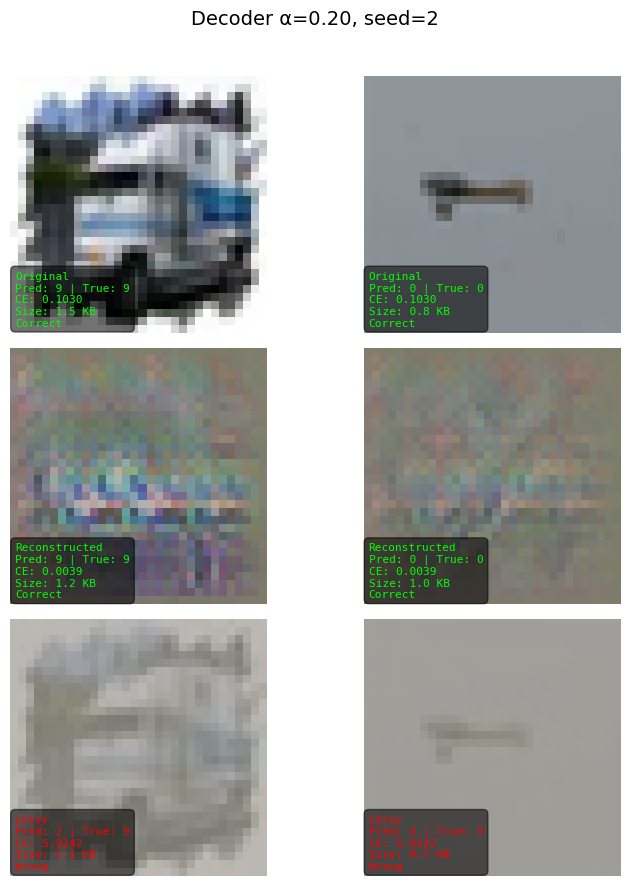


=== Evaluating Decoder α=0.20, seed=409 ===


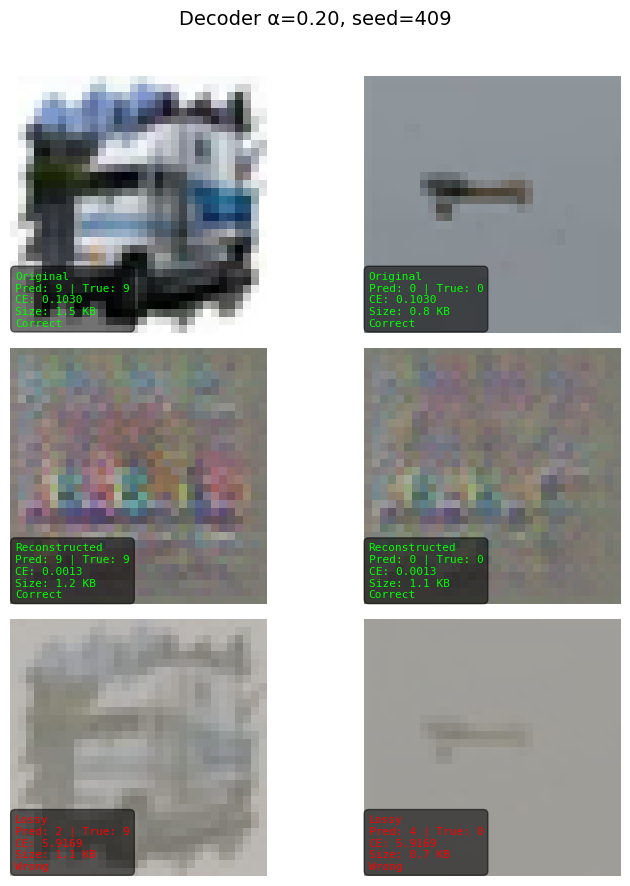


=== Evaluating Decoder α=0.20, seed=43 ===


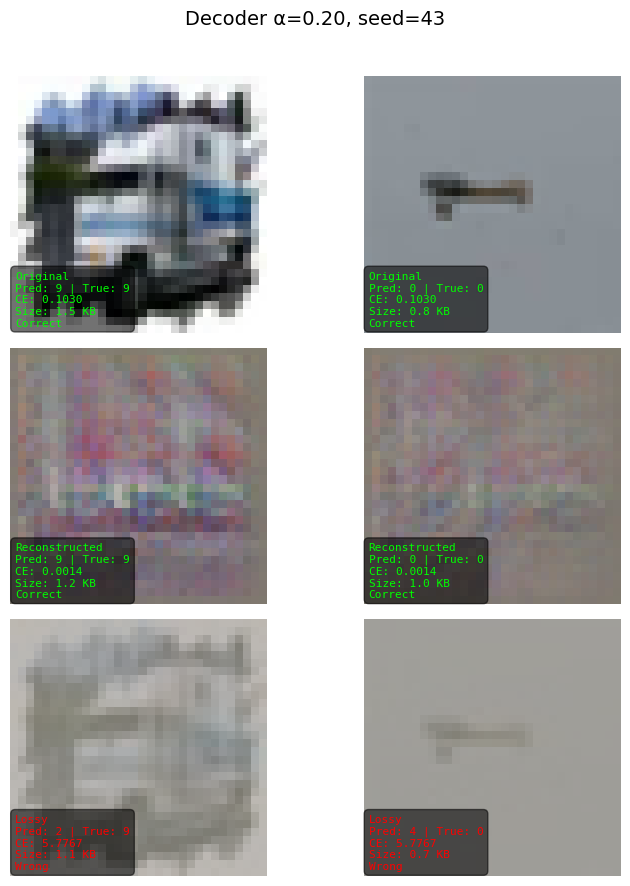


=== Evaluating Decoder α=0.35, seed=127 ===


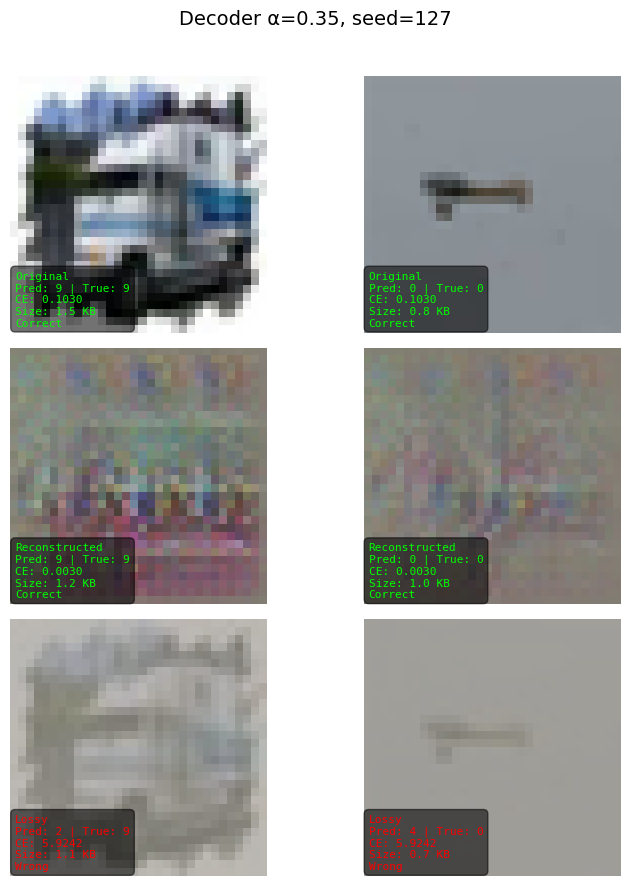


=== Evaluating Decoder α=0.35, seed=19 ===


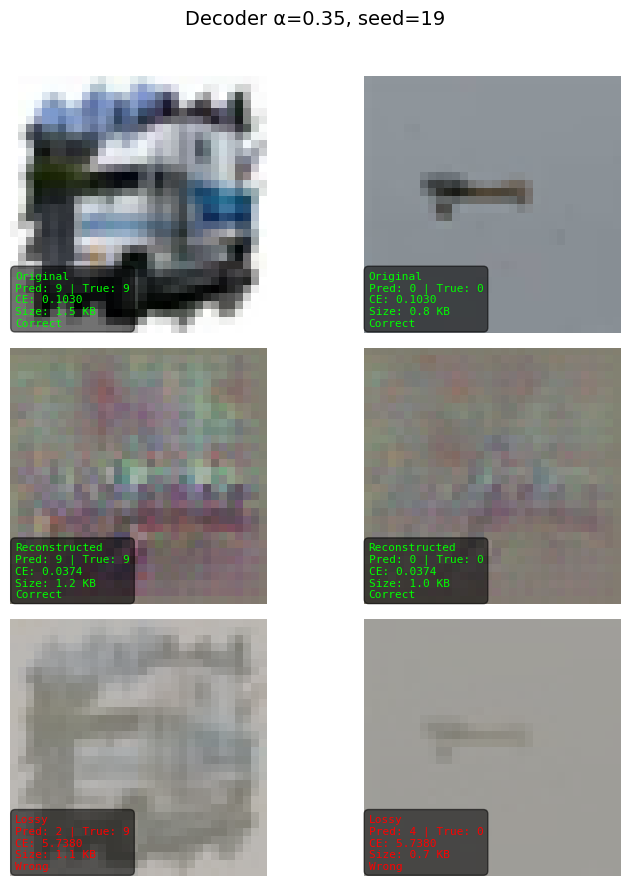


=== Evaluating Decoder α=0.35, seed=2 ===


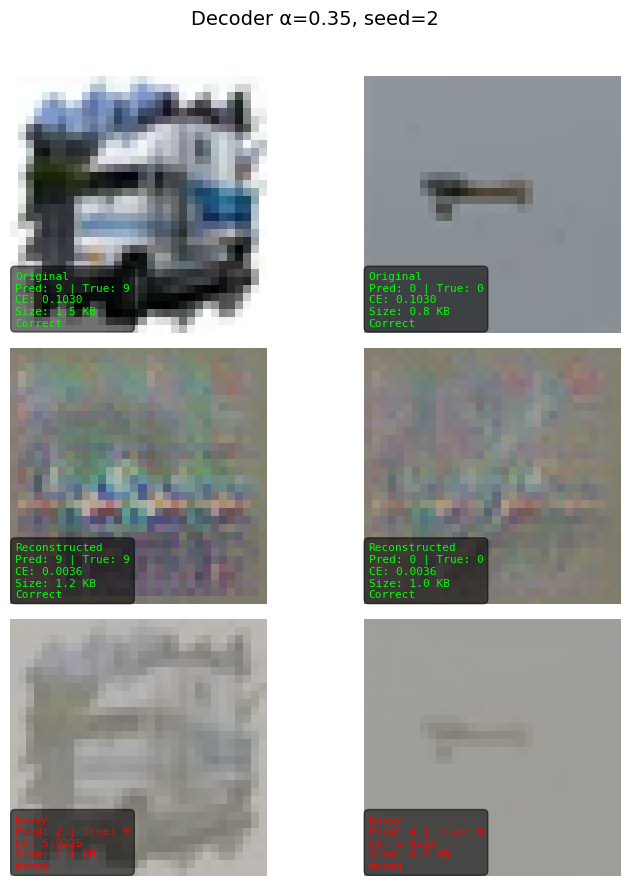


=== Evaluating Decoder α=0.35, seed=409 ===


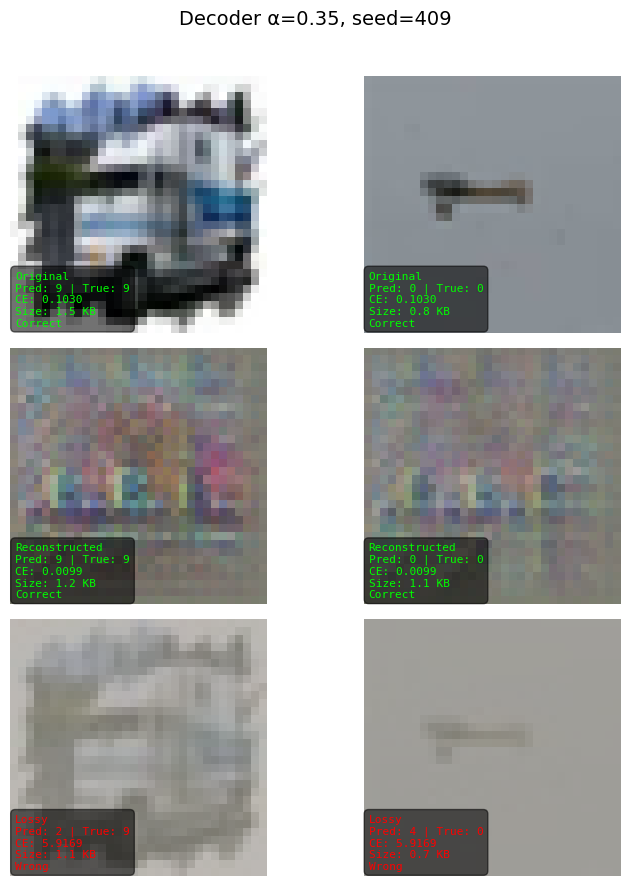


=== Evaluating Decoder α=0.35, seed=43 ===


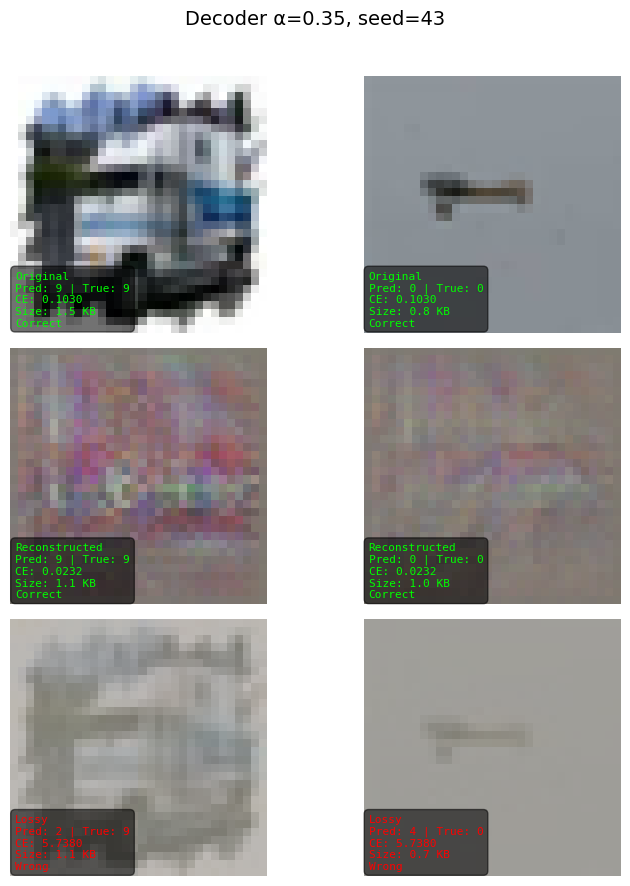


=== Evaluating Decoder α=0.97, seed=127 ===


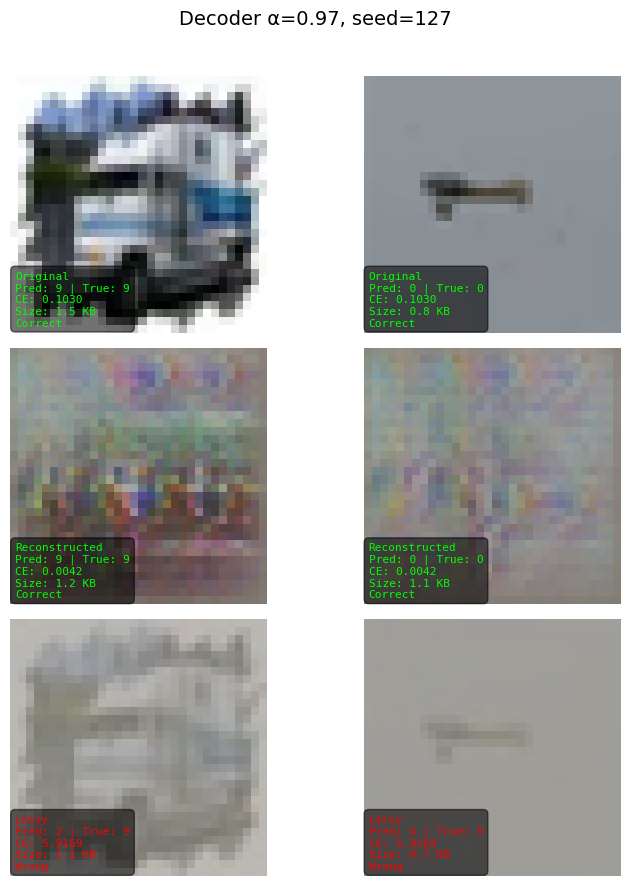


=== Evaluating Decoder α=0.97, seed=19 ===


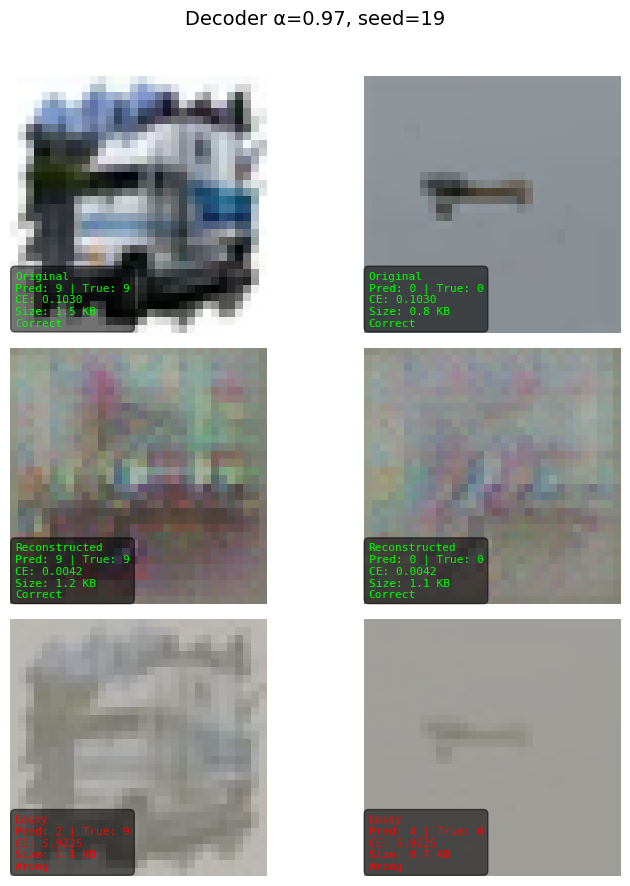


=== Evaluating Decoder α=0.97, seed=2 ===


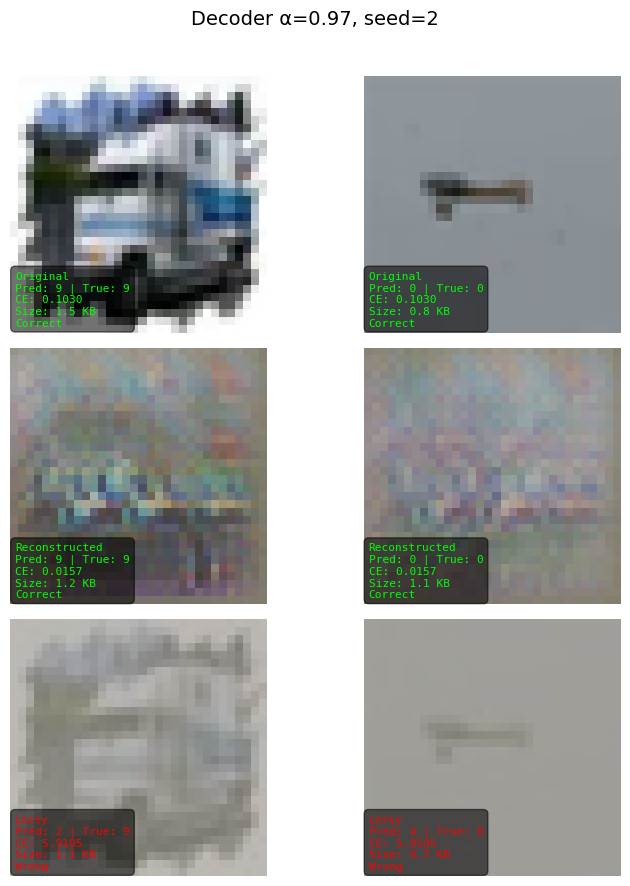


=== Evaluating Decoder α=0.97, seed=409 ===


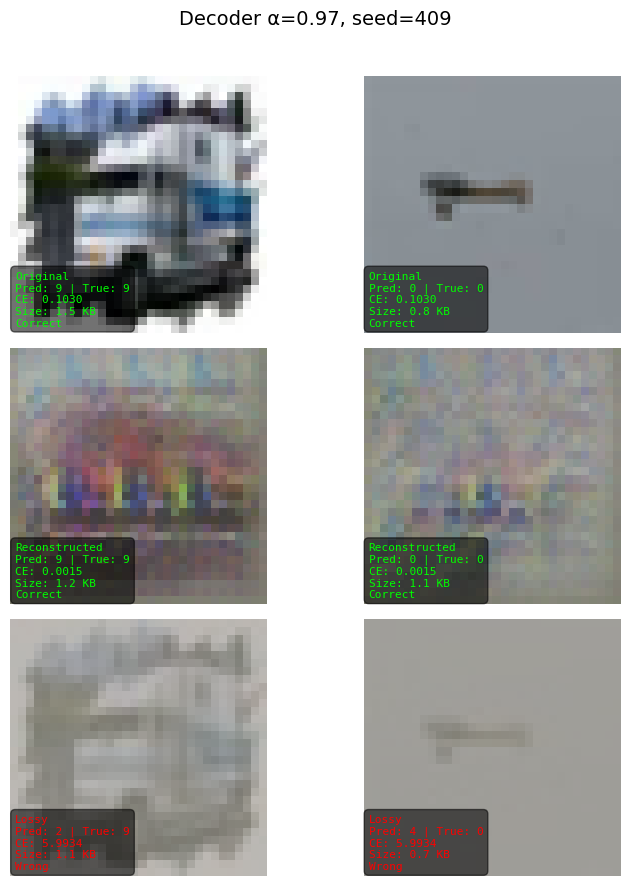


=== Evaluating Decoder α=0.97, seed=43 ===


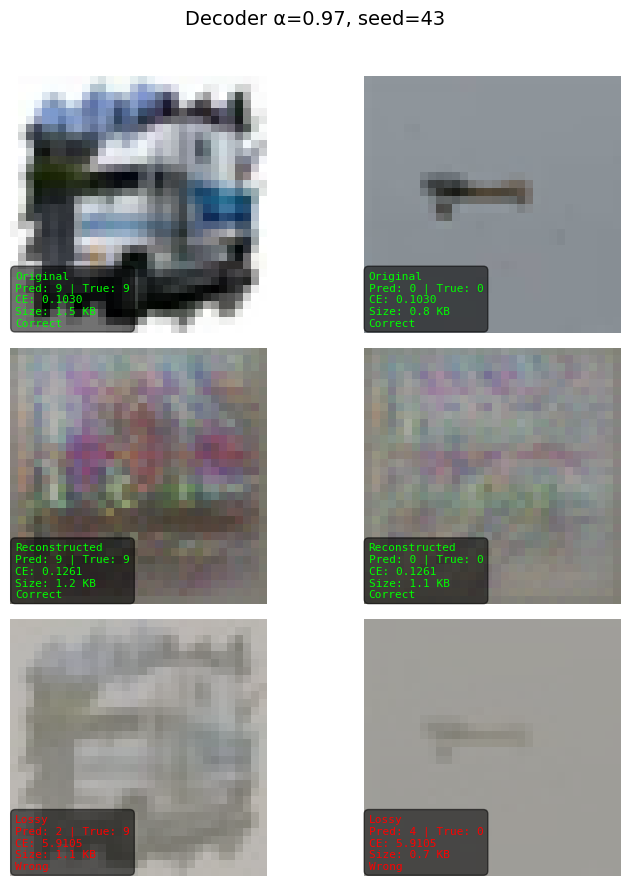

In [9]:
# Eval settings
save_dir = "SSigmoid_TargetAlpha" 
decoder_paths = sorted(glob.glob(os.path.join(save_dir, "decoder*.pth")))
print(f"Found {len(decoder_paths)} decoders in '{save_dir}' for evaluation.\n")

criterion_ce = nn.CrossEntropyLoss()

# Pick 2 random images from test set
test_images, test_labels = [], []
for i in random.sample(range(len(test_loader.dataset)), 2):
    img, label = test_loader.dataset[i]
    test_images.append(img.unsqueeze(0))
    test_labels.append(torch.tensor(label))
test_images = torch.cat(test_images).to(device)
test_labels = torch.stack(test_labels).to(device)

# Loop over all saved decoders
for path in decoder_paths:
    fname = os.path.basename(path).replace(".pth", "")  # "decoder_alpha0.00_seed127"
    # Extract alpha and seed
    fname = fname.replace("decoder_", "")  # "alpha0.00_seed127"
    alpha_str, seed_str = fname.split("_seed")  # ["alpha0.00", "127"]
    alpha_val = float(alpha_str.replace("alpha", ""))
    seed_val = int(seed_str)
    print(f"\n=== Evaluating Decoder α={alpha_val:.2f}, seed={seed_val} ===")

    # Load decoder
    decoder_curr = Decoder().to(device)
    decoder_curr.load_state_dict(torch.load(path, map_location=device))
    decoder_curr.eval()

    # Original
    with torch.no_grad():
        logits_orig = model(test_images)
        ce_orig = criterion_ce(logits_orig, test_labels).item()
        preds_orig = logits_orig.argmax(dim=1)
        acc_orig = (preds_orig == test_labels).float().mean().item()
    orig_sizes = [get_file_size(tensor_to_pil(img)) for img in test_images]

    # Recon
    with torch.no_grad():
        latents = encoder(test_images)
        recons = decoder_curr(latents)
        recons = recons * 2 - 1
        logits_recon = model(recons)
        ce_recon = criterion_ce(logits_recon, test_labels).item()
        preds_recon = logits_recon.argmax(dim=1)
        acc_recon = (preds_recon == test_labels).float().mean().item()
    recon_sizes = [get_file_size(tensor_to_pil(r)) for r in recons]

    # Lossy
    lossy_imgs = []
    for img in test_images:
        lossy_img = compress_to_target_size(img, target_bytes=int(np.mean(recon_sizes)))
        lossy_imgs.append(lossy_img.unsqueeze(0))
    lossy_batch = torch.cat(lossy_imgs).to(device)

    with torch.no_grad():
        logits_lossy = model(lossy_batch)
        ce_lossy = criterion_ce(logits_lossy, test_labels).item()
        preds_lossy = logits_lossy.argmax(dim=1)
        acc_lossy = (preds_lossy == test_labels).float().mean().item()
    lossy_sizes = [get_file_size(tensor_to_pil(l)) for l in lossy_batch]

    # Display
    fig, axs = plt.subplots(3, 2, figsize=(8, 9))
    fig.suptitle(f"Decoder α={alpha_val:.2f}, seed={seed_val}", fontsize=14)

    rows = ["Original", "Reconstructed", "Lossy"]
    imgs_show = [
        [test_images[0], test_images[1]],
        [recons[0], recons[1]],
        [lossy_batch[0], lossy_batch[1]],
    ]
    preds_all = [preds_orig, preds_recon, preds_lossy]
    ces_all = [ce_orig, ce_recon, ce_lossy]
    sizes_all = [orig_sizes, recon_sizes, lossy_sizes]

    for row in range(3):
        for col in range(2):
            ax = axs[row, col]
            ax.imshow(denormalize(imgs_show[row][col]) / 255)
            ax.axis("off")

            true_label = test_labels[col].item()
            pred_label = preds_all[row][col].item()
            correct = (true_label == pred_label)
            color = "lime" if correct else "red"

            # In-image caption box (bottom-left)
            stats = (
                f"{rows[row]}\n"
                f"Pred: {pred_label} | True: {true_label}\n"
                f"CE: {ces_all[row]:.4f}\n"
                f"Size: {sizes_all[row][col]/1024:.1f} KB\n"
                f"{'Correct' if correct else 'Wrong'}"
            )

            ax.text(
                0.02, 0.02, stats,
                transform=ax.transAxes,
                fontsize=8,
                color=color,
                va="bottom", ha="left",
                family="monospace",
                bbox=dict(facecolor="black", alpha=0.55, boxstyle="round,pad=0.4")
            )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


## Mirrored ResNet Decoder

In [10]:
class MirrorBasicBlock(nn.Module):
    """Reverse of a ResNet BasicBlock, preserving residual skip."""
    def __init__(self, block):
        super().__init__()
        # Mirror convs
        self.deconv2 = self.mirror_conv(block.conv2)
        self.bn2 = nn.BatchNorm2d(block.conv2.in_channels)
        self.deconv1 = self.mirror_conv(block.conv1)
        self.bn1 = nn.BatchNorm2d(block.conv1.in_channels)
        self.relu = nn.ReLU(inplace=True)

        # Mirror downsample (if present)
        if block.downsample is not None:
            down = block.downsample[0]
            self.upsample = nn.Sequential(
                self.mirror_conv(down),
                nn.BatchNorm2d(down.in_channels)
            )
        else:
            self.upsample = None

    def mirror_conv(self, conv):
        """Create a ConvTranspose2d layer that mirrors a given Conv2d layer."""
        return nn.ConvTranspose2d(
            in_channels=conv.out_channels,
            out_channels=conv.in_channels,
            kernel_size=conv.kernel_size,
            stride=conv.stride,
            padding=conv.padding,
            output_padding=1 if conv.stride[0] > 1 else 0,
            bias=False,
        )

    def forward(self, x):
        identity = x
        out = self.deconv2(x)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.deconv1(out)
        out = self.bn1(out)

        if self.upsample is not None:
            identity = self.upsample(identity)

        out += identity
        out = self.relu(out)
        return out


### Mirrored ResNet Tanh Decoder

In [11]:
class Decoder(nn.Module):
    def __init__(self):
        super(Decoder, self).__init__()

        base = models.resnet18(weights=None)

        def mirror_layer(layer):
            blocks = [MirrorBasicBlock(b) for b in reversed(layer)]
            return nn.Sequential(*blocks)

        self.up3 = mirror_layer(base.layer3)
        self.up2 = mirror_layer(base.layer2)
        self.up1 = mirror_layer(base.layer1)

        # Mirror of initial conv (7x7 stride=2)
        self.final = nn.ConvTranspose2d(
            64, 3, kernel_size=7, stride=2, padding=3, output_padding=1
        )

        # Extra step: bring from 16×16 -> 32×32
        self.upsample_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(3, 3, kernel_size=3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.up3(x)
        x = self.up2(x)
        x = self.up1(x)
        x = self.final(x)
        x = self.upsample_final(x)
        return x

decoder = Decoder().to(device)
model = model.to(device)

Found 15 decoders in 'MRTanh_TargetAlpha' for evaluation.


=== Evaluating Decoder α=0.18, seed=127 ===


/tmp/ipykernel_209358/3203032333.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  decoder_curr.load_state_dict(torch.load(path, map_location=device))


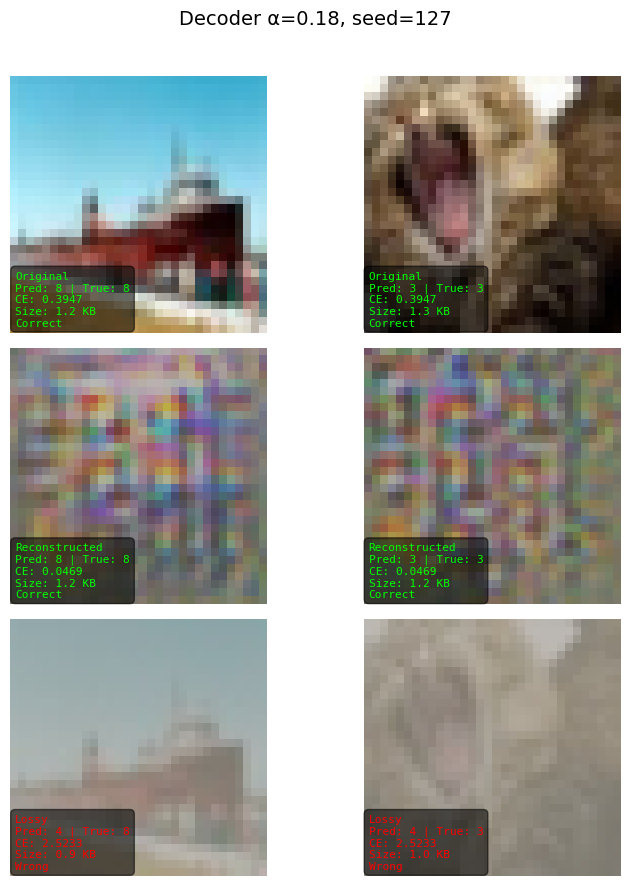


=== Evaluating Decoder α=0.18, seed=19 ===


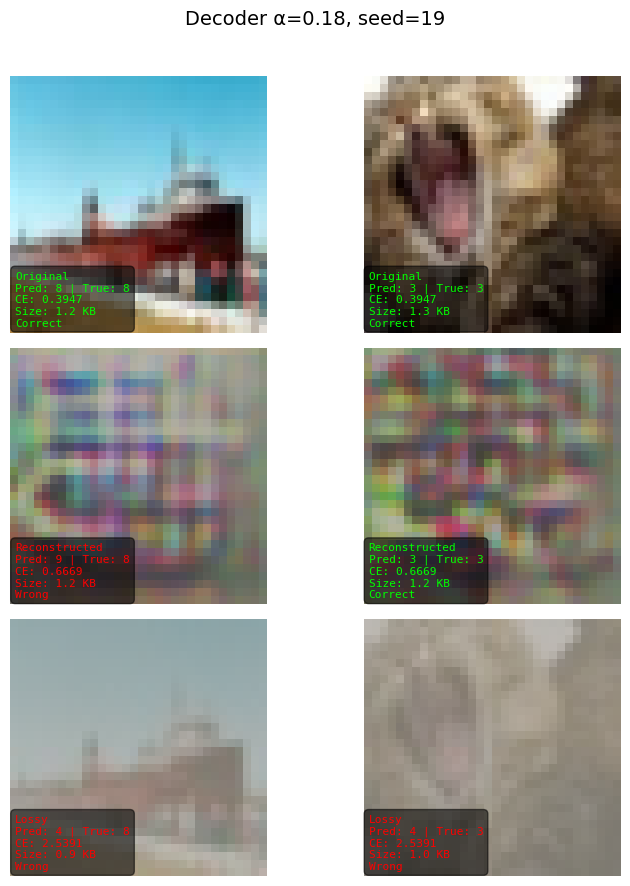


=== Evaluating Decoder α=0.18, seed=2 ===


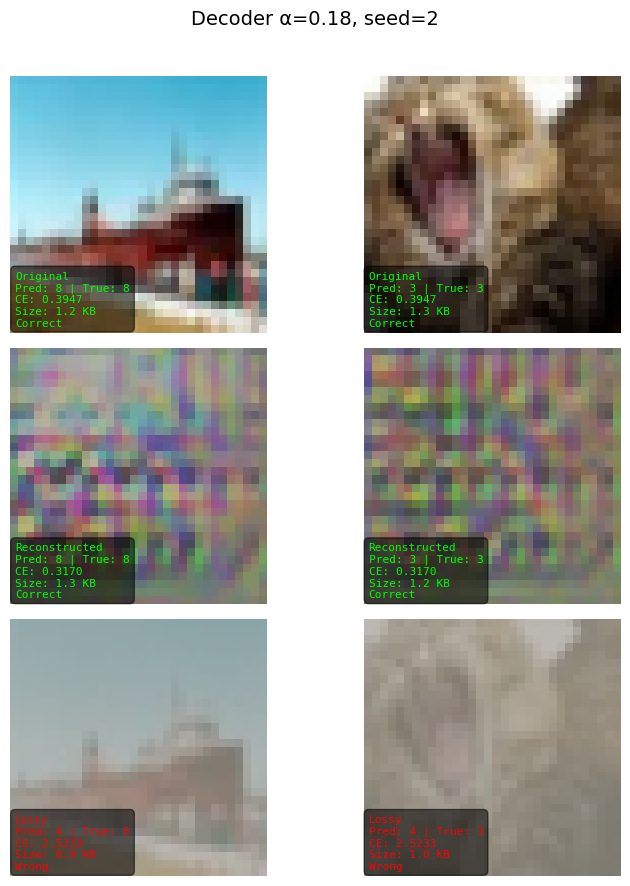


=== Evaluating Decoder α=0.18, seed=409 ===


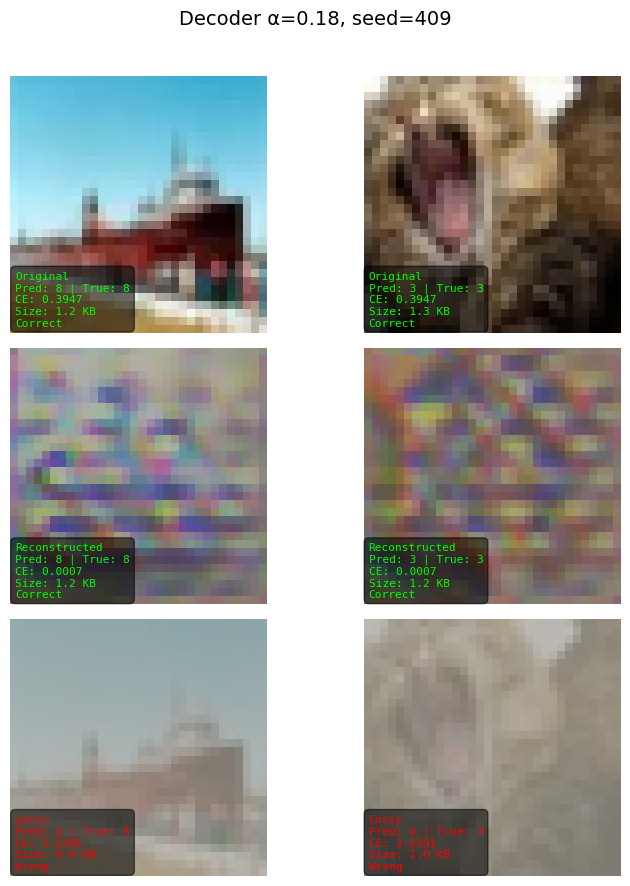


=== Evaluating Decoder α=0.18, seed=43 ===


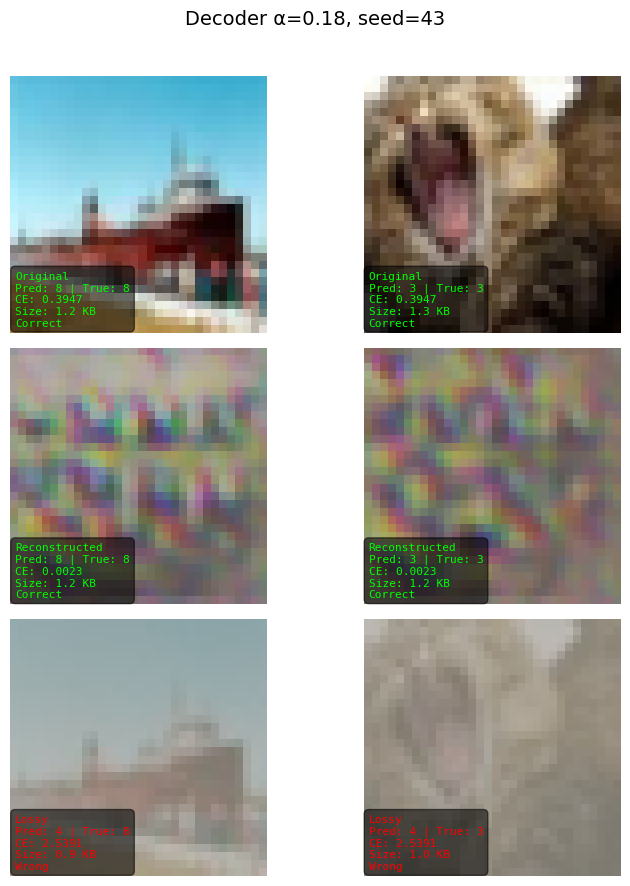


=== Evaluating Decoder α=0.24, seed=127 ===


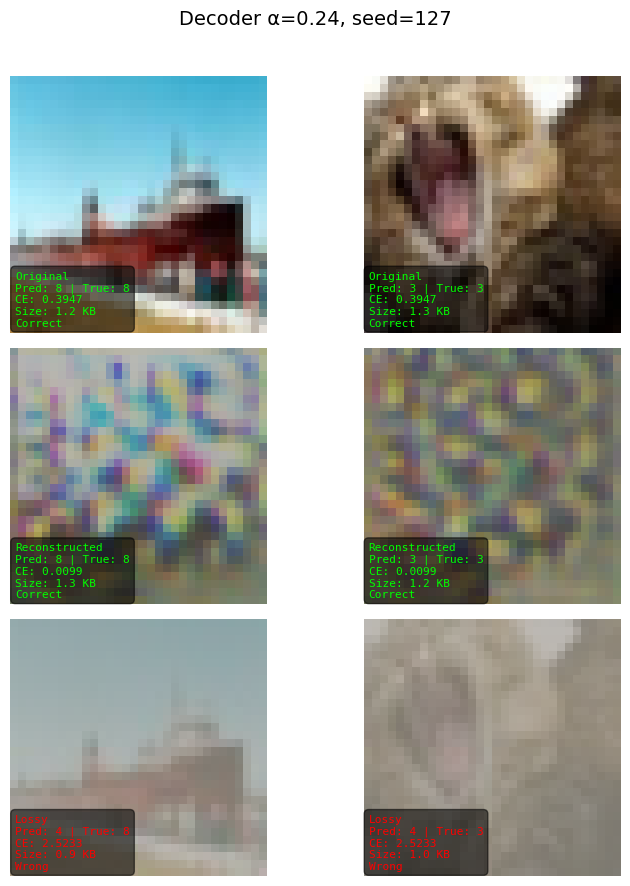


=== Evaluating Decoder α=0.24, seed=19 ===


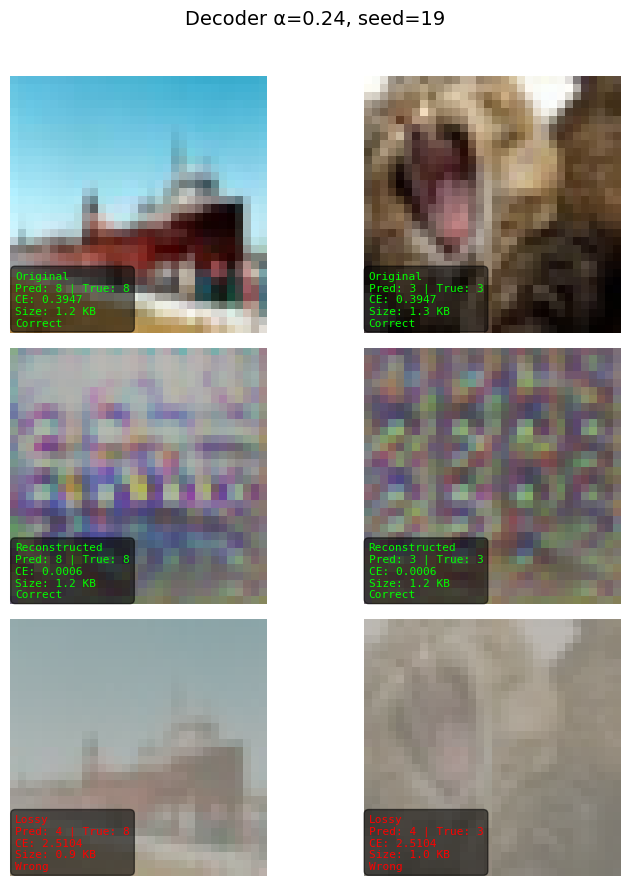


=== Evaluating Decoder α=0.24, seed=2 ===


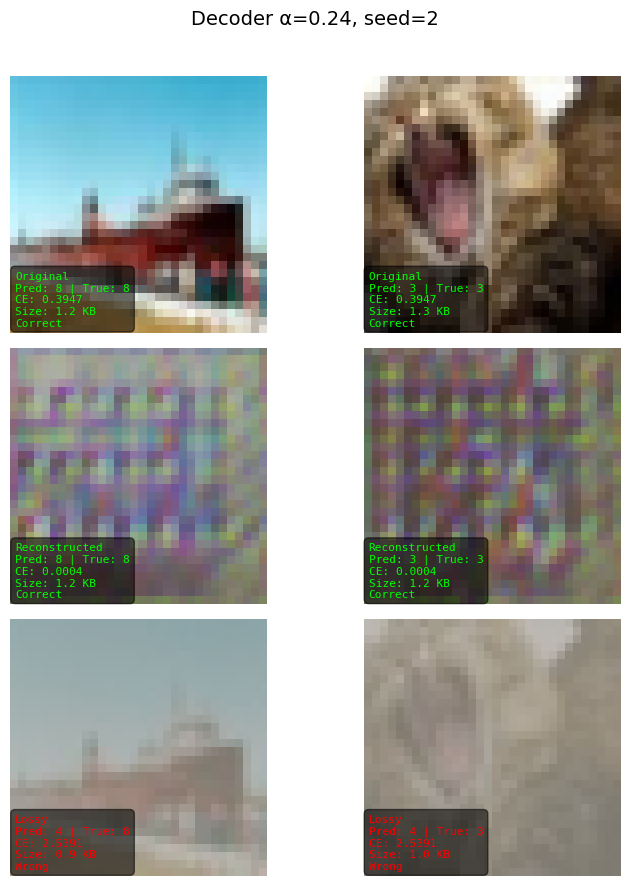


=== Evaluating Decoder α=0.24, seed=409 ===


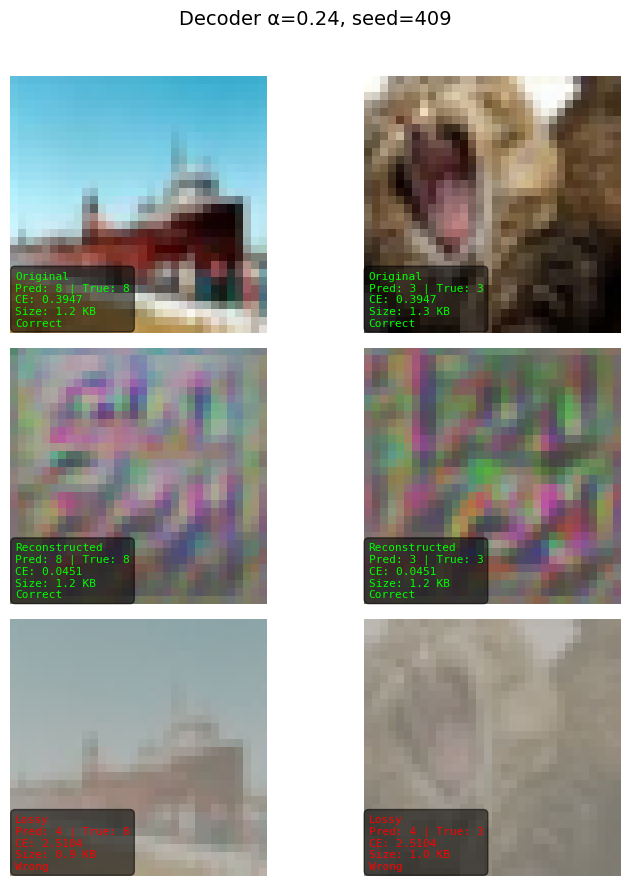


=== Evaluating Decoder α=0.24, seed=43 ===


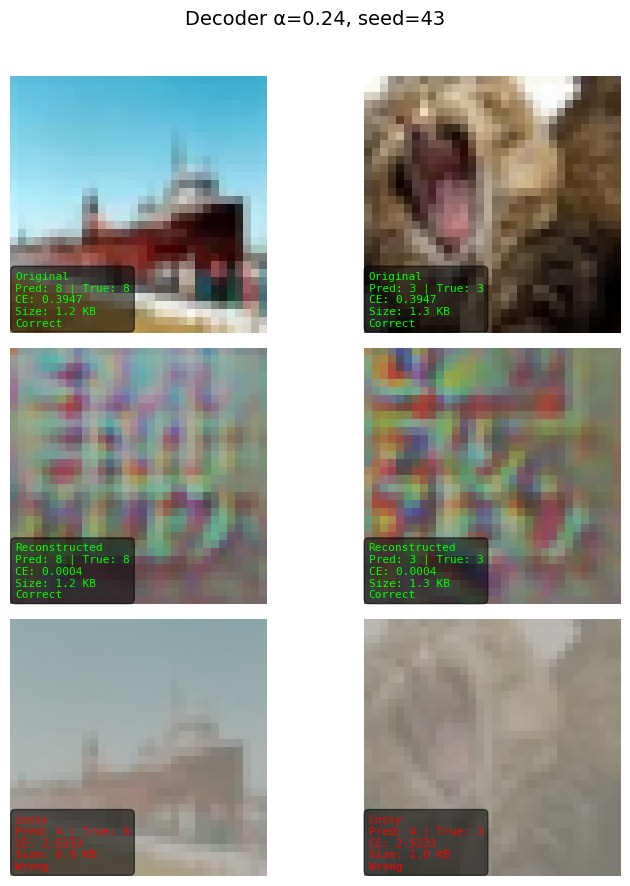


=== Evaluating Decoder α=0.27, seed=127 ===


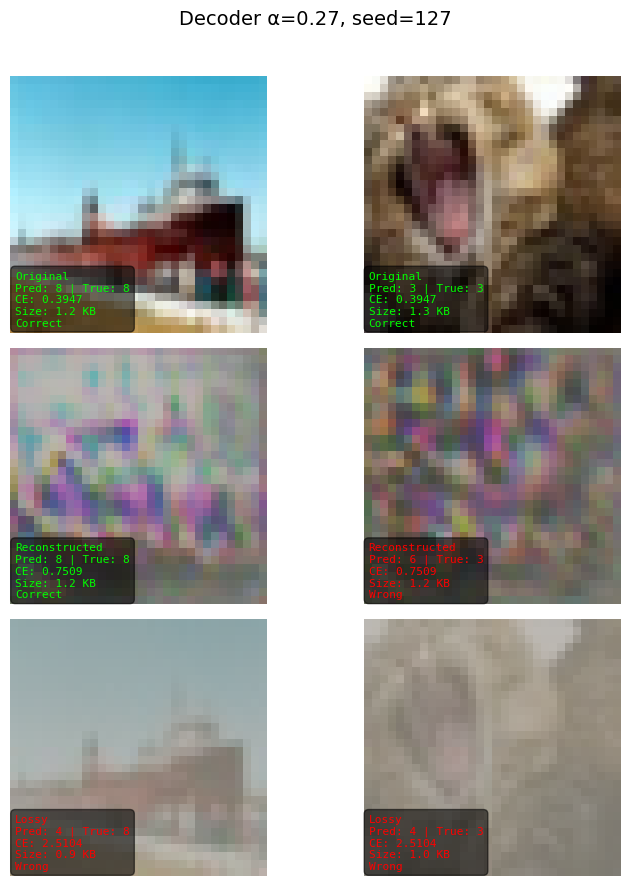


=== Evaluating Decoder α=0.27, seed=19 ===


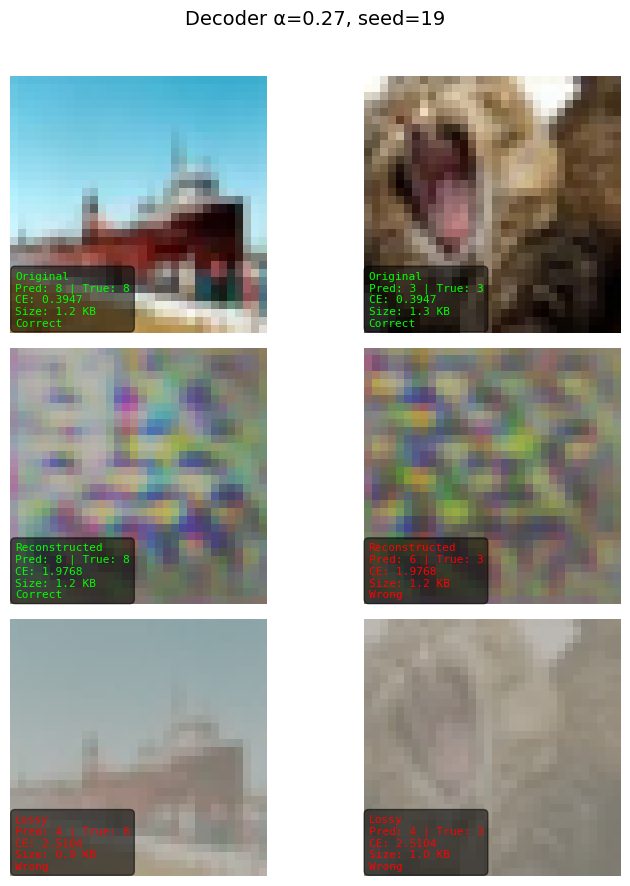


=== Evaluating Decoder α=0.27, seed=2 ===


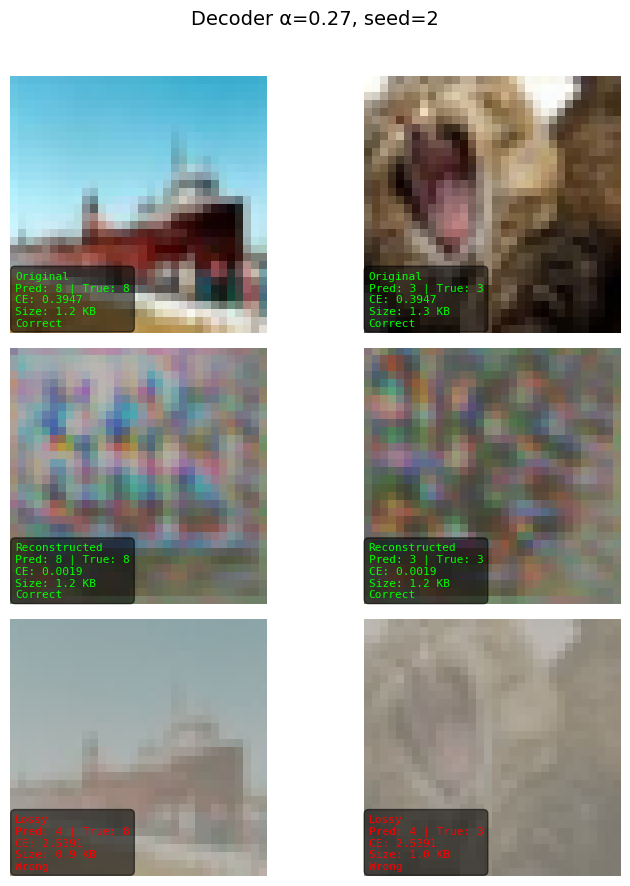


=== Evaluating Decoder α=0.27, seed=409 ===


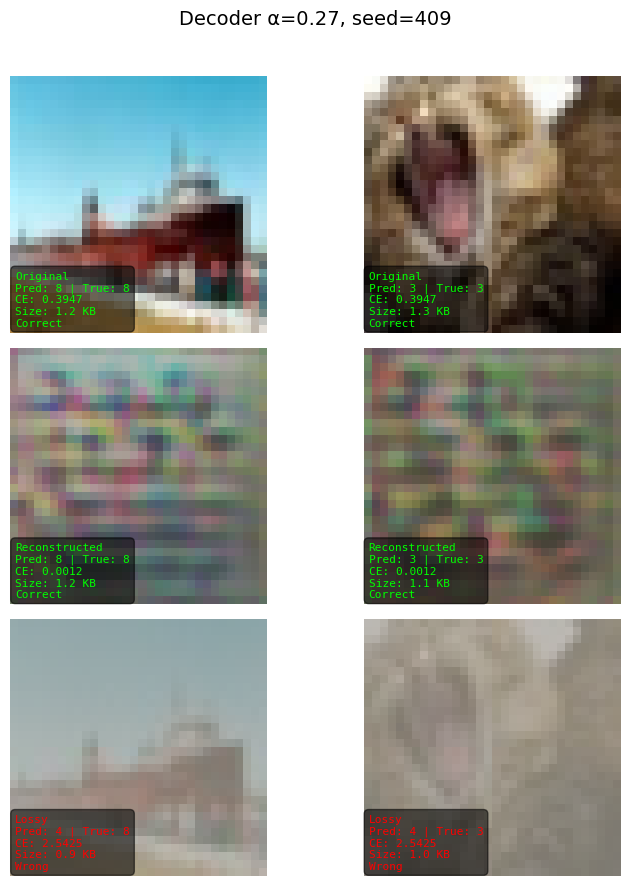


=== Evaluating Decoder α=0.27, seed=43 ===


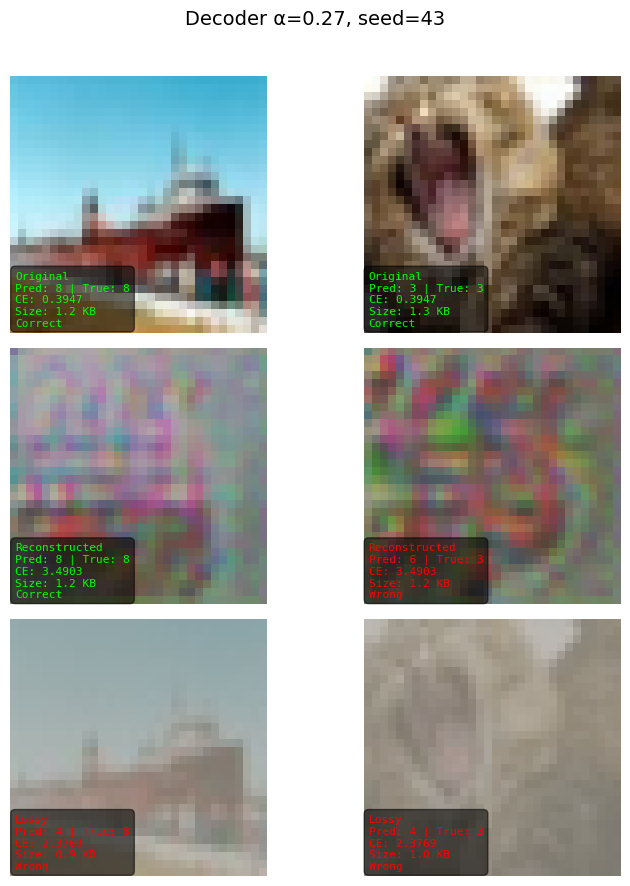

In [12]:
# Eval settings
save_dir = "MRTanh_TargetAlpha" 
decoder_paths = sorted(glob.glob(os.path.join(save_dir, "decoder*.pth")))
print(f"Found {len(decoder_paths)} decoders in '{save_dir}' for evaluation.\n")

criterion_ce = nn.CrossEntropyLoss()

# Pick 2 random images from test set
test_images, test_labels = [], []
for i in random.sample(range(len(test_loader.dataset)), 2):
    img, label = test_loader.dataset[i]
    test_images.append(img.unsqueeze(0))
    test_labels.append(torch.tensor(label))
test_images = torch.cat(test_images).to(device)
test_labels = torch.stack(test_labels).to(device)

# Loop over all saved decoders
for path in decoder_paths:
    fname = os.path.basename(path).replace(".pth", "")  # "decoder0.01_seed127"
    # Extract alpha and seed
    fname = fname.replace("decoder", "")  # "0.01_seed127"
    alpha_str, seed_str = fname.split("_seed")
    alpha_val = float(alpha_str)
    seed_val = int(seed_str)
    print(f"\n=== Evaluating Decoder α={alpha_val:.2f}, seed={seed_val} ===")

    # Load decoder
    decoder_curr = Decoder().to(device)
    decoder_curr.load_state_dict(torch.load(path, map_location=device))
    decoder_curr.eval()

    # Original
    with torch.no_grad():
        logits_orig = model(test_images)
        ce_orig = criterion_ce(logits_orig, test_labels).item()
        preds_orig = logits_orig.argmax(dim=1)
        acc_orig = (preds_orig == test_labels).float().mean().item()
    orig_sizes = [get_file_size(tensor_to_pil(img)) for img in test_images]

    # Recon
    with torch.no_grad():
        latents = encoder(test_images)
        recons = decoder_curr(latents)
        logits_recon = model(recons)
        ce_recon = criterion_ce(logits_recon, test_labels).item()
        preds_recon = logits_recon.argmax(dim=1)
        acc_recon = (preds_recon == test_labels).float().mean().item()
    recon_sizes = [get_file_size(tensor_to_pil(r)) for r in recons]

    # Lossy
    lossy_imgs = []
    for img in test_images:
        lossy_img = compress_to_target_size(img, target_bytes=int(np.mean(recon_sizes)))
        lossy_imgs.append(lossy_img.unsqueeze(0))
    lossy_batch = torch.cat(lossy_imgs).to(device)

    with torch.no_grad():
        logits_lossy = model(lossy_batch)
        ce_lossy = criterion_ce(logits_lossy, test_labels).item()
        preds_lossy = logits_lossy.argmax(dim=1)
        acc_lossy = (preds_lossy == test_labels).float().mean().item()
    lossy_sizes = [get_file_size(tensor_to_pil(l)) for l in lossy_batch]

    # Display
    fig, axs = plt.subplots(3, 2, figsize=(8, 9))
    fig.suptitle(f"Decoder α={alpha_val:.2f}, seed={seed_val}", fontsize=14)

    rows = ["Original", "Reconstructed", "Lossy"]
    imgs_show = [
        [test_images[0], test_images[1]],
        [recons[0], recons[1]],
        [lossy_batch[0], lossy_batch[1]],
    ]
    preds_all = [preds_orig, preds_recon, preds_lossy]
    ces_all = [ce_orig, ce_recon, ce_lossy]
    sizes_all = [orig_sizes, recon_sizes, lossy_sizes]

    for row in range(3):
        for col in range(2):
            ax = axs[row, col]
            ax.imshow(denormalize(imgs_show[row][col]) / 255)
            ax.axis("off")

            true_label = test_labels[col].item()
            pred_label = preds_all[row][col].item()
            correct = (true_label == pred_label)
            color = "lime" if correct else "red"

            # In-image caption box (bottom-left)
            stats = (
                f"{rows[row]}\n"
                f"Pred: {pred_label} | True: {true_label}\n"
                f"CE: {ces_all[row]:.4f}\n"
                f"Size: {sizes_all[row][col]/1024:.1f} KB\n"
                f"{'Correct' if correct else 'Wrong'}"
            )

            ax.text(
                0.02, 0.02, stats,
                transform=ax.transAxes,
                fontsize=8,
                color=color,
                va="bottom", ha="left",
                family="monospace",
                bbox=dict(facecolor="black", alpha=0.55, boxstyle="round,pad=0.4")
            )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


### Mirrored ResNet Sigmoid Decoder

In [13]:
class Decoder(nn.Module):
    def __init__(self):
        super(Decoder, self).__init__()

        base = models.resnet18(weights=None)

        def mirror_layer(layer):
            blocks = [MirrorBasicBlock(b) for b in reversed(layer)]
            return nn.Sequential(*blocks)

        self.up3 = mirror_layer(base.layer3)
        self.up2 = mirror_layer(base.layer2)
        self.up1 = mirror_layer(base.layer1)

        # Mirror of initial conv (7x7 stride=2)
        self.final = nn.ConvTranspose2d(
            64, 3, kernel_size=7, stride=2, padding=3, output_padding=1
        )

        # Extra step: bring from 16×16 -> 32×32
        self.upsample_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(3, 3, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.up3(x)
        x = self.up2(x)
        x = self.up1(x)
        x = self.final(x)
        x = self.upsample_final(x)
        return x

decoder = Decoder().to(device)
model = model.to(device)

Found 15 decoders in 'MRSigmoid_TargetAlpha' for evaluation.


=== Evaluating Decoder α=0.00, seed=127 ===


/tmp/ipykernel_209358/3702137974.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  decoder_curr.load_state_dict(torch.load(path, map_location=device))


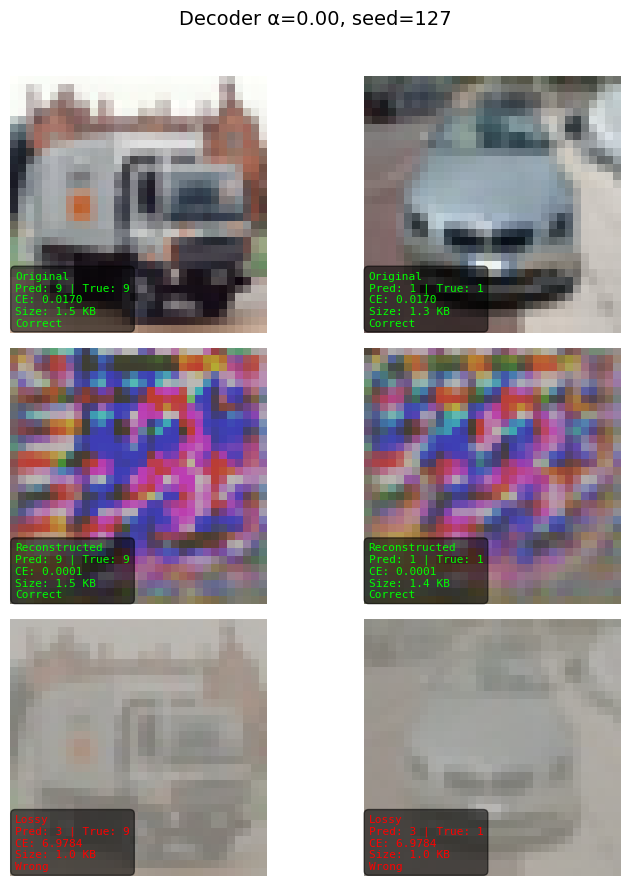


=== Evaluating Decoder α=0.00, seed=19 ===


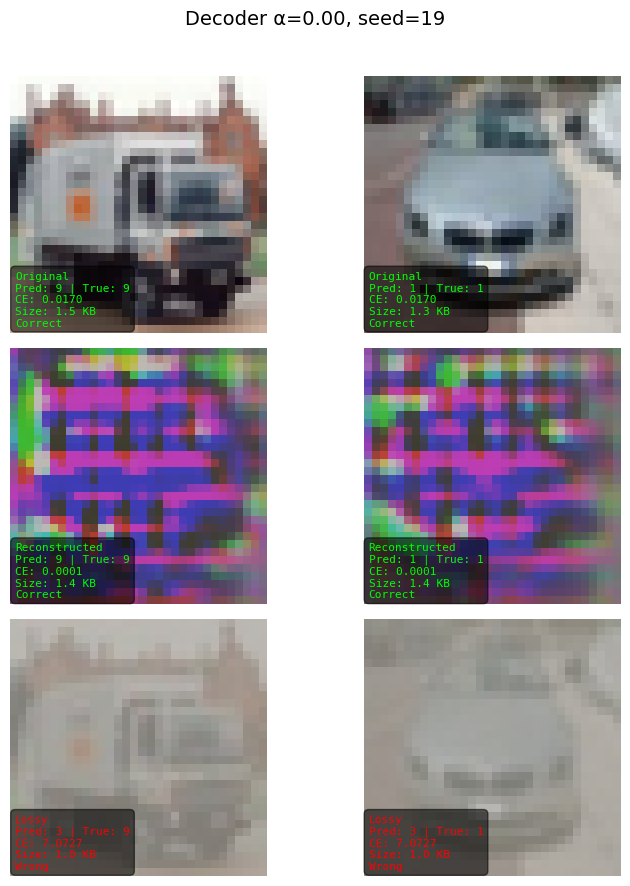


=== Evaluating Decoder α=0.00, seed=2 ===


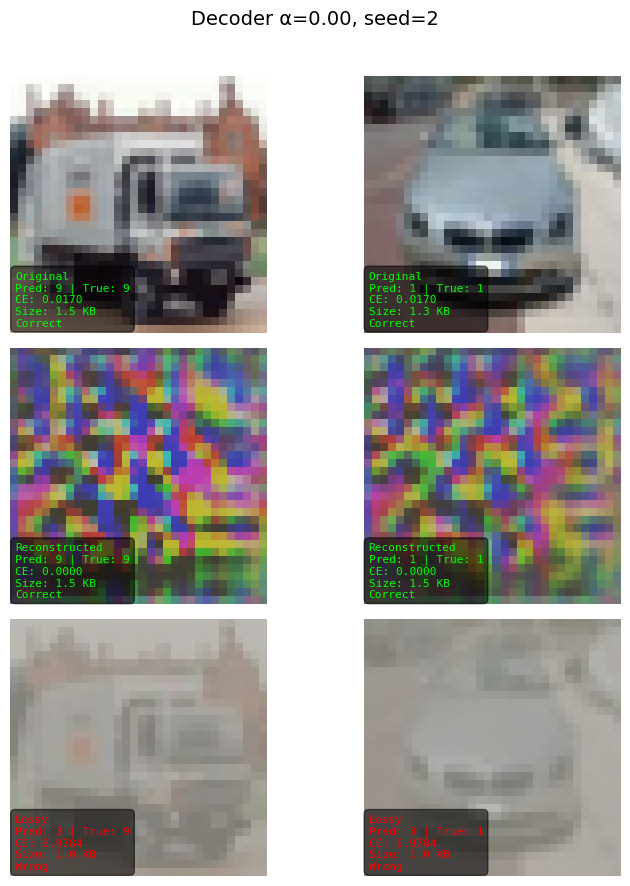


=== Evaluating Decoder α=0.00, seed=409 ===


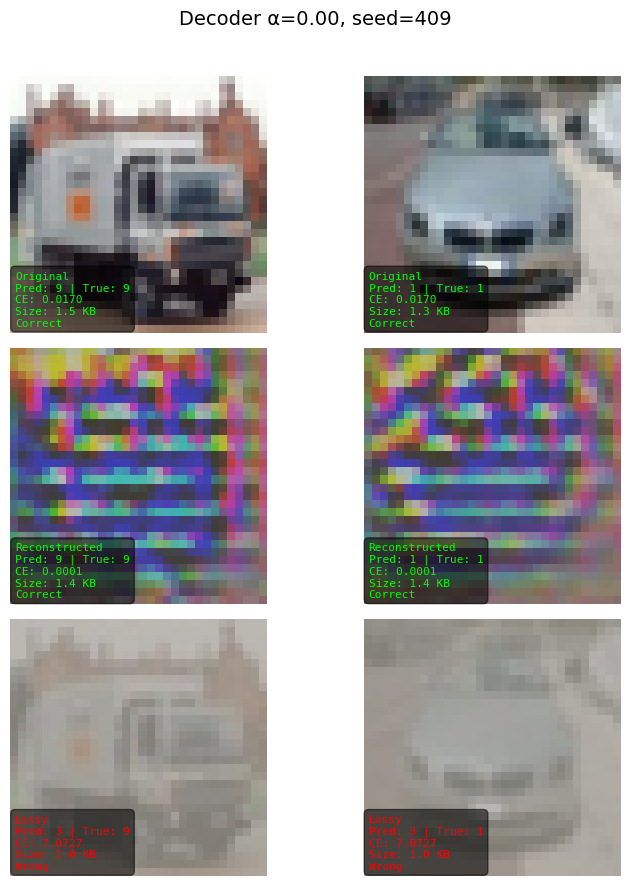


=== Evaluating Decoder α=0.00, seed=43 ===


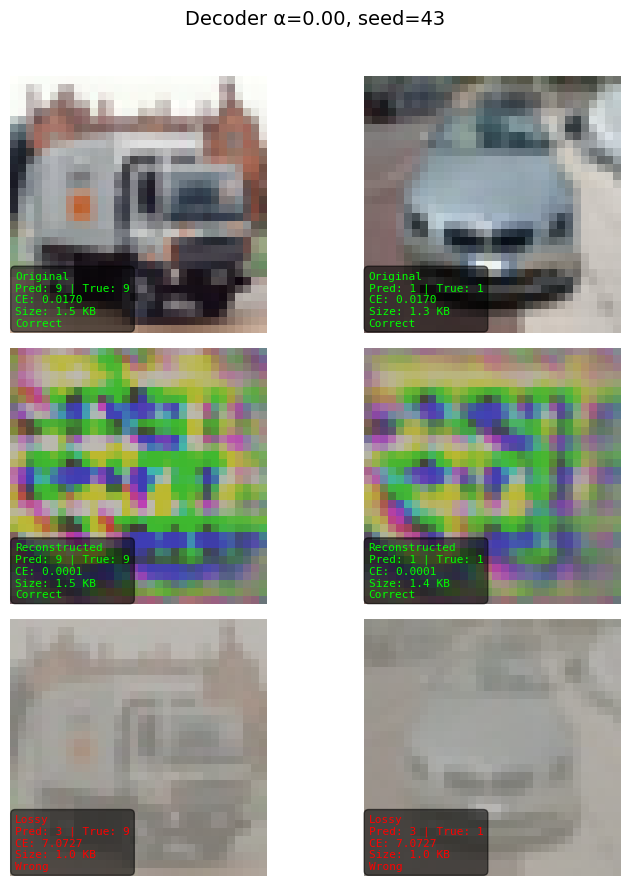


=== Evaluating Decoder α=0.08, seed=127 ===


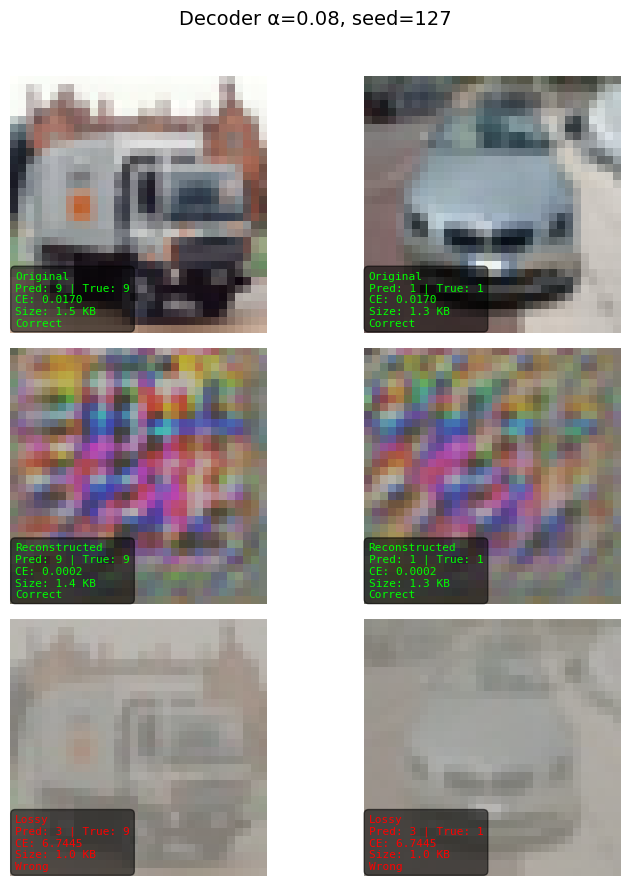


=== Evaluating Decoder α=0.08, seed=19 ===


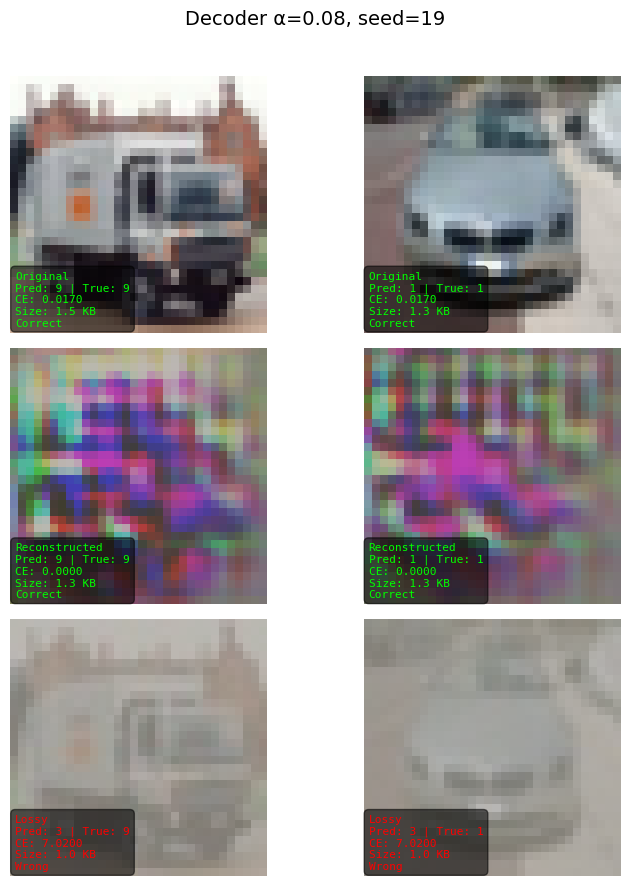


=== Evaluating Decoder α=0.08, seed=2 ===


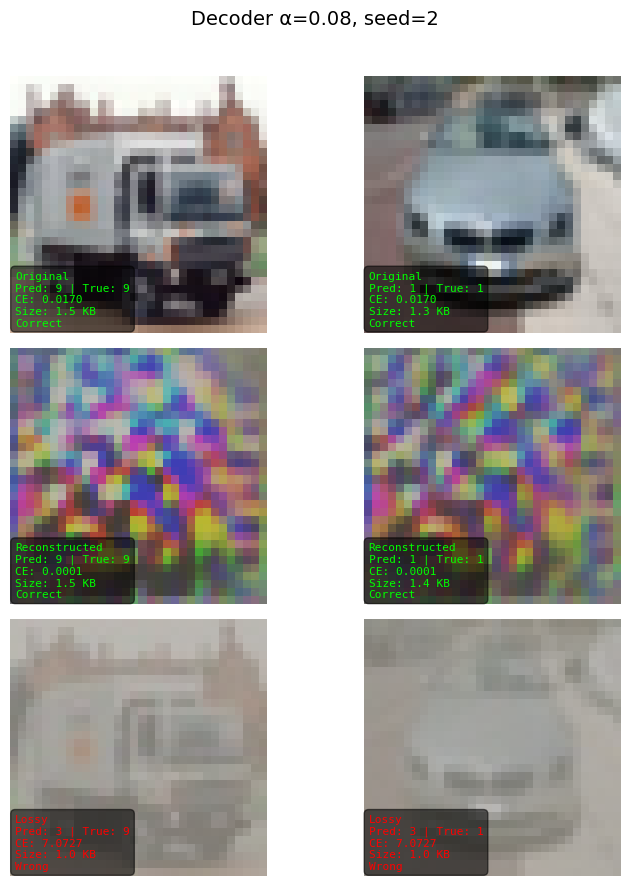


=== Evaluating Decoder α=0.08, seed=409 ===


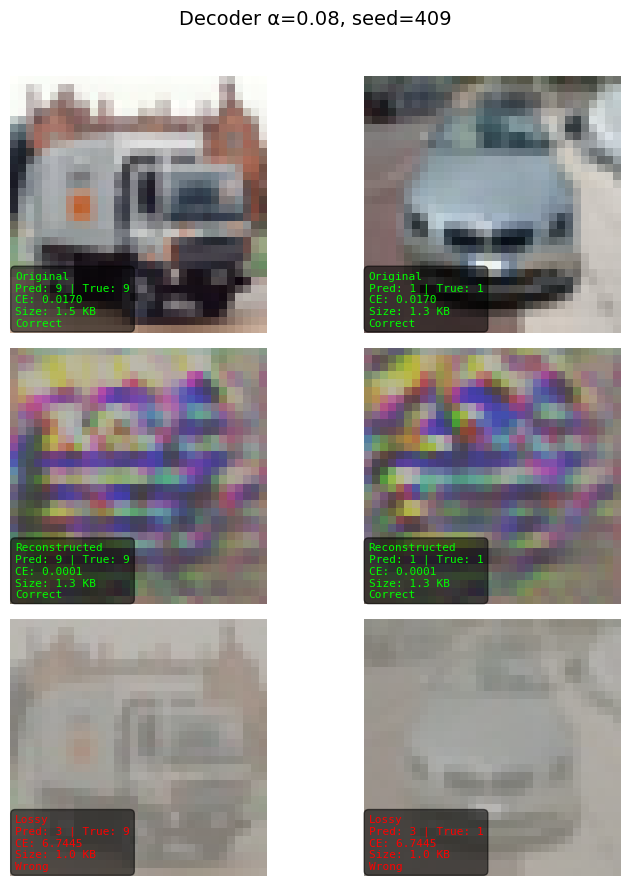


=== Evaluating Decoder α=0.08, seed=43 ===


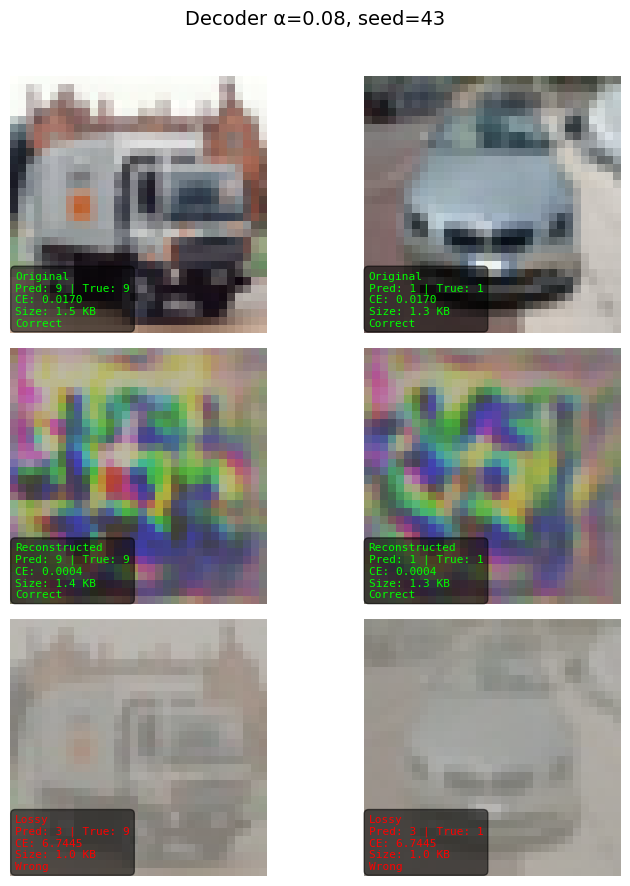


=== Evaluating Decoder α=0.32, seed=127 ===


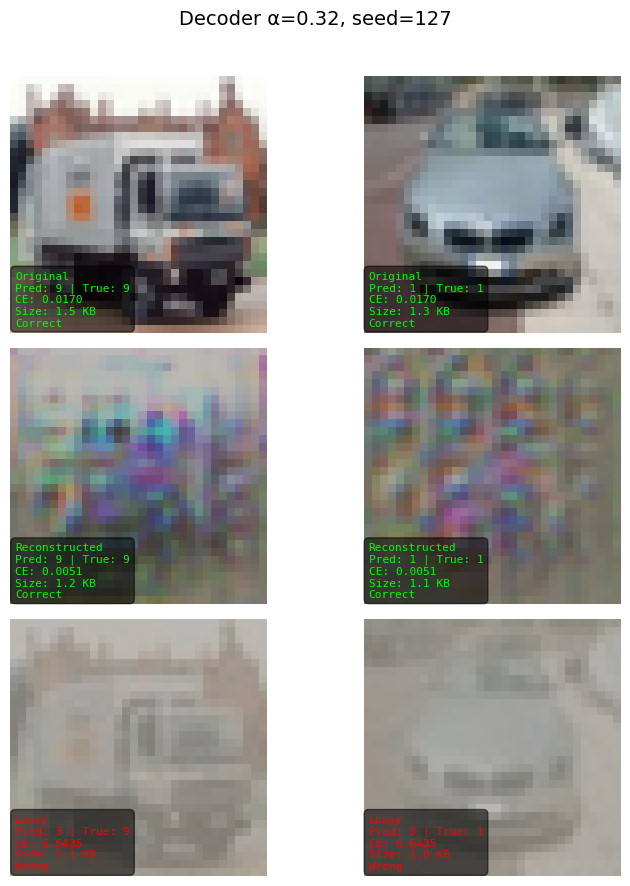


=== Evaluating Decoder α=0.32, seed=19 ===


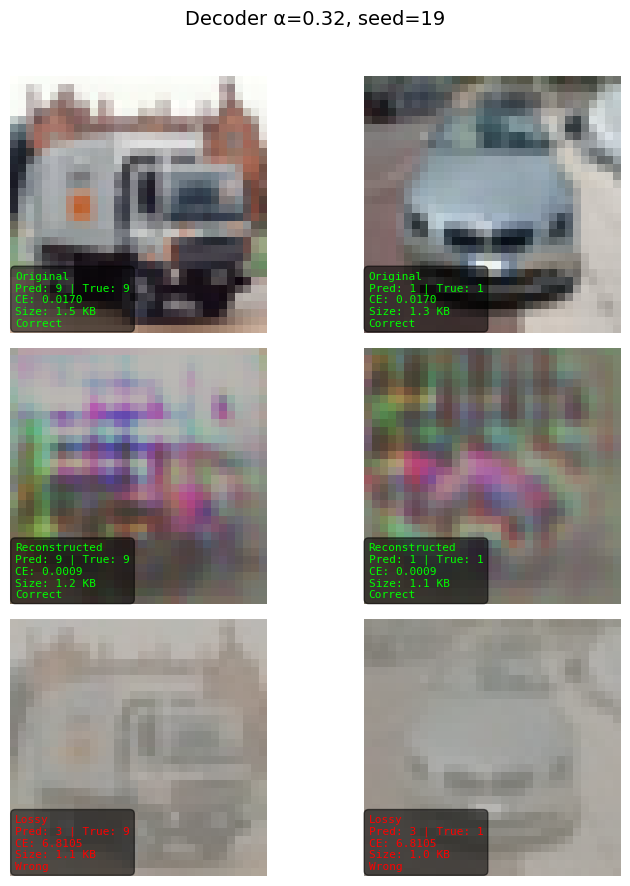


=== Evaluating Decoder α=0.32, seed=2 ===


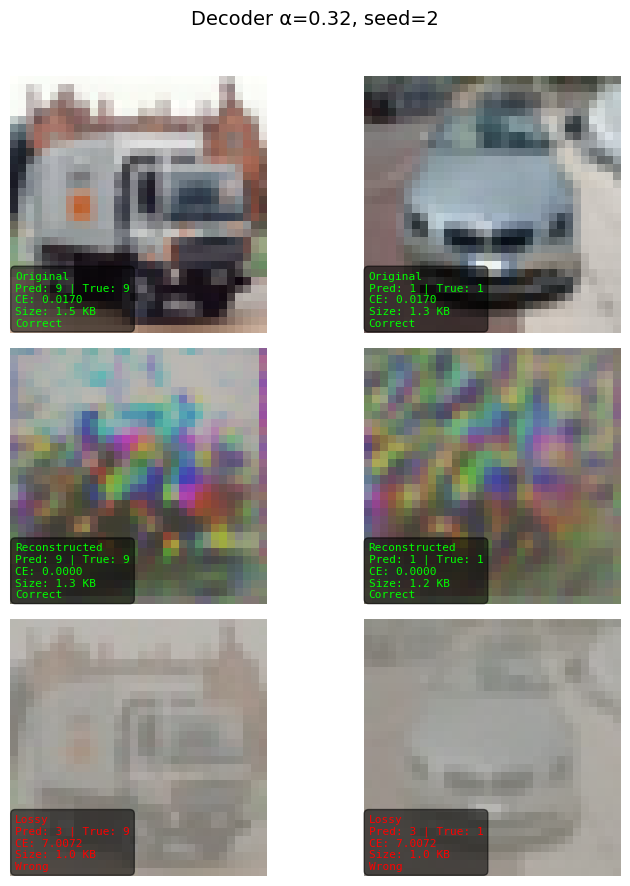


=== Evaluating Decoder α=0.32, seed=409 ===


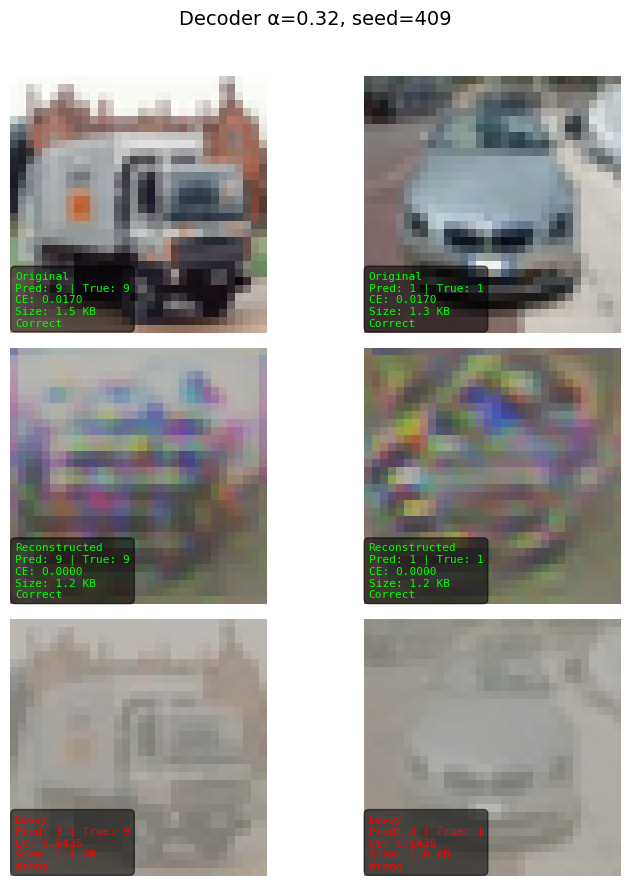


=== Evaluating Decoder α=0.32, seed=43 ===


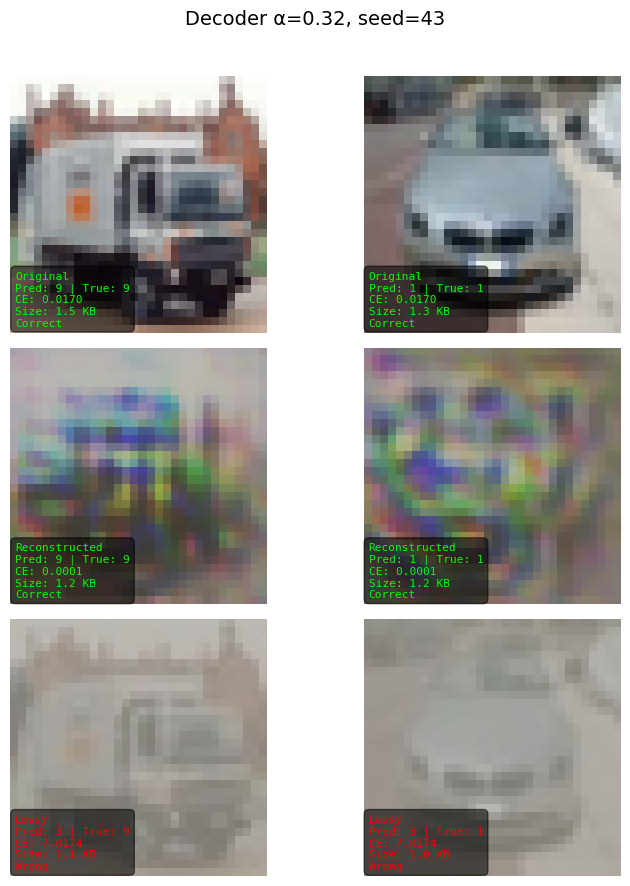

In [14]:
# Eval settings
save_dir = "MRSigmoid_TargetAlpha" 
decoder_paths = sorted(glob.glob(os.path.join(save_dir, "decoder*.pth")))
print(f"Found {len(decoder_paths)} decoders in '{save_dir}' for evaluation.\n")

criterion_ce = nn.CrossEntropyLoss()

# Pick 2 random images from test set
test_images, test_labels = [], []
for i in random.sample(range(len(test_loader.dataset)), 2):
    img, label = test_loader.dataset[i]
    test_images.append(img.unsqueeze(0))
    test_labels.append(torch.tensor(label))
test_images = torch.cat(test_images).to(device)
test_labels = torch.stack(test_labels).to(device)

# Loop over all saved decoders
for path in decoder_paths:
    fname = os.path.basename(path).replace(".pth", "")  # "decoder_alpha0.00_seed127"
    # Extract alpha and seed
    fname = fname.replace("decoder_", "")  # "alpha0.00_seed127"
    alpha_str, seed_str = fname.split("_seed")  # ["alpha0.00", "127"]
    alpha_val = float(alpha_str.replace("alpha", ""))
    seed_val = int(seed_str)
    print(f"\n=== Evaluating Decoder α={alpha_val:.2f}, seed={seed_val} ===")

    # Load decoder
    decoder_curr = Decoder().to(device)
    decoder_curr.load_state_dict(torch.load(path, map_location=device))
    decoder_curr.eval()

    # Original
    with torch.no_grad():
        logits_orig = model(test_images)
        ce_orig = criterion_ce(logits_orig, test_labels).item()
        preds_orig = logits_orig.argmax(dim=1)
        acc_orig = (preds_orig == test_labels).float().mean().item()
    orig_sizes = [get_file_size(tensor_to_pil(img)) for img in test_images]

    # Recon
    with torch.no_grad():
        latents = encoder(test_images)
        recons = decoder_curr(latents)
        recons = recons * 2 - 1
        logits_recon = model(recons)
        ce_recon = criterion_ce(logits_recon, test_labels).item()
        preds_recon = logits_recon.argmax(dim=1)
        acc_recon = (preds_recon == test_labels).float().mean().item()
    recon_sizes = [get_file_size(tensor_to_pil(r)) for r in recons]

    # Lossy
    lossy_imgs = []
    for img in test_images:
        lossy_img = compress_to_target_size(img, target_bytes=int(np.mean(recon_sizes)))
        lossy_imgs.append(lossy_img.unsqueeze(0))
    lossy_batch = torch.cat(lossy_imgs).to(device)

    with torch.no_grad():
        logits_lossy = model(lossy_batch)
        ce_lossy = criterion_ce(logits_lossy, test_labels).item()
        preds_lossy = logits_lossy.argmax(dim=1)
        acc_lossy = (preds_lossy == test_labels).float().mean().item()
    lossy_sizes = [get_file_size(tensor_to_pil(l)) for l in lossy_batch]

    # Display
    fig, axs = plt.subplots(3, 2, figsize=(8, 9))
    fig.suptitle(f"Decoder α={alpha_val:.2f}, seed={seed_val}", fontsize=14)

    rows = ["Original", "Reconstructed", "Lossy"]
    imgs_show = [
        [test_images[0], test_images[1]],
        [recons[0], recons[1]],
        [lossy_batch[0], lossy_batch[1]],
    ]
    preds_all = [preds_orig, preds_recon, preds_lossy]
    ces_all = [ce_orig, ce_recon, ce_lossy]
    sizes_all = [orig_sizes, recon_sizes, lossy_sizes]

    for row in range(3):
        for col in range(2):
            ax = axs[row, col]
            ax.imshow(denormalize(imgs_show[row][col]) / 255)
            ax.axis("off")

            true_label = test_labels[col].item()
            pred_label = preds_all[row][col].item()
            correct = (true_label == pred_label)
            color = "lime" if correct else "red"

            # In-image caption box (bottom-left)
            stats = (
                f"{rows[row]}\n"
                f"Pred: {pred_label} | True: {true_label}\n"
                f"CE: {ces_all[row]:.4f}\n"
                f"Size: {sizes_all[row][col]/1024:.1f} KB\n"
                f"{'Correct' if correct else 'Wrong'}"
            )

            ax.text(
                0.02, 0.02, stats,
                transform=ax.transAxes,
                fontsize=8,
                color=color,
                va="bottom", ha="left",
                family="monospace",
                bbox=dict(facecolor="black", alpha=0.55, boxstyle="round,pad=0.4")
            )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
